# Week 2 - Statistical Analysis and Hypothesis Testing Framework
**Does Wealth Burn Carbon? CO2 emissions vs economic development, 1990-2022**

This notebook executes the whole pipeline end to end: acquisition (cached) -> cleaning -> integrity tests -> hypothesis tests H1-H7 -> figures. All statistics are produced by `src/tests.py`; hypotheses, tests, alpha and multiplicity rules were fixed in `docs/analysis_plan.md` *before* any test was run.

In [1]:
import sys, os, subprocess
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'src'))
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30); pd.set_option('display.max_colwidth', 80)
print('project root:', ROOT)

project root: C:\Users\kanis\Desktop\AI Side Hustles\Virtual Internship Projects and Reports\Task 2


## 1. Acquisition (cached raw data, never overwritten)

In [2]:
import acquire
acquire.main()

cached: owid-co2-data.csv
cached: wb_country_metadata.csv
cached: wb_NY.GDP.PCAP.KD.csv
cached: wb_NY.GDP.PCAP.PP.KD.csv
cached: wb_SP.POP.TOTL.csv
cached: wb_SP.URB.TOTL.IN.ZS.csv
cached: wb_NV.IND.TOTL.ZS.csv

Manifest:
  owid-co2-data.csv                2026-11-05 10:09:15  14,377,942 bytes  sha256=7f78e2b218ce...
  wb_country_metadata.csv          2026-11-05 10:09:16      21,405 bytes  sha256=ec0788af0e02...
  wb_NY.GDP.PCAP.KD.csv            2026-11-05 10:09:16     375,456 bytes  sha256=6dbff6747c2a...
  wb_NY.GDP.PCAP.PP.KD.csv         2026-11-05 10:09:16     370,477 bytes  sha256=22af2902d070...
  wb_SP.POP.TOTL.csv               2026-11-05 10:09:17     326,481 bytes  sha256=57cf0d2a7dae...
  wb_SP.URB.TOTL.IN.ZS.csv         2026-11-05 10:09:17     378,982 bytes  sha256=335e37ab4bdc...
  wb_NV.IND.TOTL.ZS.csv            2026-11-05 10:09:18     364,013 bytes  sha256=ecd1aff6e43e...


## 2. Cleaning (Week 1 rules) and sample flow

In [3]:
import clean
clean.main()

[wb_meta] drop World Bank aggregates (region == 'Aggregates'): 296 -> 217  
[wb_ind:NY.GDP.PCAP.KD] keep country rows only: 8,778 -> 7,161  459 null values kept as missing (not imputed)
[wb_ind:NY.GDP.PCAP.PP.KD] keep country rows only: 8,778 -> 7,161  761 null values kept as missing (not imputed)
[wb_ind:SP.POP.TOTL] keep country rows only: 8,778 -> 7,161  0 null values kept as missing (not imputed)
[wb_ind:SP.URB.TOTL.IN.ZS] keep country rows only: 8,778 -> 7,161  0 null values kept as missing (not imputed)
[wb_ind:NV.IND.TOTL.ZS] keep country rows only: 8,778 -> 7,161  1,119 null values kept as missing (not imputed)


[owid_years] restrict to 1990-2022: 50,411 -> 8,375  
[owid_crosswalk] manual crosswalk Kosovo -> XKX: 33 -> 0  rows changed (not dropped)
[owid_agg] drop OWID rows with no ISO3 (aggregates, regions, shipping, aviation...): 8,375 -> 7,227  35 non-country entities
[join] outer join OWID x World Bank on (iso3, year): 14,388 -> 7,557  both=6,831, owid_only=396, wb_only=330
[range:urban_pct] shares outside 0-100 set to NaN: 7,161 -> 7,161  
[range:industry_pct] shares outside 0-100 set to NaN: 6,042 -> 6,042  
[logguard:co2_pc] non-positive values excluded from log transforms: 7,045 -> 7,035  
[logguard:gdp_pc] non-positive values excluded from log transforms: 6,702 -> 6,702  
[logguard:gdp_pc_ppp] non-positive values excluded from log transforms: 6,400 -> 6,400  



panel (7557, 15), cross-section (229, 17), paired (229, 18), row-level log 9,367 rows
hypothesis  n_remaining
        H1          198
        H2          205
        H3          146
        H4          198
        H5           74
        H6          184
        H7          194


In [4]:
print(pd.read_csv('results/cleaning_log.csv')[['step','rule','rows_before','rows_after','note']].to_string())
flow = pd.read_csv('results/sample_flow.csv')
flow.groupby('hypothesis').tail(1)[['hypothesis','n_remaining']].rename(columns={'n_remaining':'n entering test'})

                        step                                                                      rule  rows_before  rows_after                                             note
0                    wb_meta                       drop World Bank aggregates (region == 'Aggregates')          296         217                                              NaN
1      wb_ind:NY.GDP.PCAP.KD                                                    keep country rows only         8778        7161    459 null values kept as missing (not imputed)
2   wb_ind:NY.GDP.PCAP.PP.KD                                                    keep country rows only         8778        7161    761 null values kept as missing (not imputed)
3         wb_ind:SP.POP.TOTL                                                    keep country rows only         8778        7161      0 null values kept as missing (not imputed)
4   wb_ind:SP.URB.TOTL.IN.ZS                                                    keep country rows only         8778

,hypothesis,n entering test
2,H1,198
5,H2,205
9,H3,146
13,H4,198
17,H5,74
23,H6,184
28,H7,194


## 3. Data-integrity tests (pytest)

In [5]:
out = subprocess.run([sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider'], cwd=ROOT, capture_output=True, text=True)
print(out.stdout[-1500:]); assert out.returncode == 0, 'pytest failed'

.........................                                                [100%]
25 passed in 3.45s



## 4. Hypothesis tests H1-H7 (assumption checks printed first, then primary test, then robustness)
The console output below is the real output of `src/tests.py`. Fixed seed = 42; B = 10,000 resamples.

In [6]:
import importlib, tests as T
importlib.reload(T)
results = T.run_all()

{'H1': 198, 'H2': 205, 'H3': 146, 'H4': 198, 'H5': 74, 'H6': 184, 'H7': 194}

=== H1: GDP pc vs CO2 pc, 2022 (Spearman, one-sided rho > 0) ===
   CHECK H1 Shapiro-Wilk: log10 GDP pc: stat=0.9803, p=0.006875 -> NOT normal (p<=0.05) n=198
   CHECK H1 Shapiro-Wilk: log10 CO2 pc: stat=0.9659, p=9.827e-05 -> NOT normal (p<=0.05) n=198
   CHECK H1 Shapiro-Wilk: raw GDP pc (before log): stat=0.7133, p=3.426e-18 -> NOT normal (p<=0.05) n=198
   CHECK H1 Shapiro-Wilk: raw CO2 pc (before log): stat=0.7326, p=1.371e-17 -> NOT normal (p<=0.05) n=198
   CHECK H1 skewness raw vs log10 CO2 pc: stat=2.583, p=nan -> log transform reduces skew skew raw=2.58, skew log10=-0.58
   CHECK H1 outliers |z|>3 on log10 CO2 pc: stat=0, p=nan -> none 


   H1 [primary] Spearman rho (one-sided, greater): n=198, stat=0.8548, p=4.976e-58, Spearman rho=0.855 [0.802, 0.893] 
   H1 [companion: Pearson on log10 values] Pearson r (one-sided, greater): n=198, stat=0.8518, p=3.062e-57, Pearson r=0.852 [0.808, 0.886] 


   H1 [robustness: permutation test] Spearman permutation (B=10,000): n=198, stat=0.8548, p=9.999e-05, Spearman rho=0.855 [nan, nan] 


   H1 [robustness: PPP GDP] Spearman rho (one-sided, greater): n=195, stat=0.8686, p=4.637e-61, Spearman rho=0.869 [0.814, 0.907] 


   H1 [robustness: excluding population < 1 million] Spearman rho (one-sided, greater): n=155, stat=0.8623, p=2.277e-47, Spearman rho=0.862 [0.805, 0.900] 


   H1 [robustness: excluding oil/gas exporters] Spearman rho (one-sided, greater): n=175, stat=0.8839, p=2.639e-59, Spearman rho=0.884 [0.834, 0.918] 

=== H2: CO2 pc differs across four income groups (Kruskal-Wallis) ===
   CHECK H2 Shapiro-Wilk: raw CO2 pc, Low income: stat=0.4832, p=2.562e-08 -> NOT normal (p<=0.05) n=25
   CHECK H2 Shapiro-Wilk: log10 CO2 pc, Low income: stat=0.8801, p=0.006941 -> NOT normal (p<=0.05) n=25
   CHECK H2 Shapiro-Wilk: raw CO2 pc, Lower middle income: stat=0.8096, p=2.623e-06 -> NOT normal (p<=0.05) n=47
   CHECK H2 Shapiro-Wilk: log10 CO2 pc, Lower middle income: stat=0.9625, p=0.1353 -> normal (p>0.05) n=47
   CHECK H2 Shapiro-Wilk: raw CO2 pc, Upper middle income: stat=0.8075, p=2.494e-07 -> NOT normal (p<=0.05) n=59
   CHECK H2 Shapiro-Wilk: log10 CO2 pc, Upper middle income: stat=0.9812, p=0.4946 -> normal (p>0.05) n=59
   CHECK H2 Shapiro-Wilk: raw CO2 pc, High income: stat=0.7901, p=6.714e-09 -> NOT normal (p<=0.05) n=74
   CHECK H2 Shapiro-Wilk

... (22 outputs left out)

   H6 [robustness: excluding oil/gas exporters] Chi-square test of independence (df=3): n=161, stat=57.63, p=1.882e-12, Cramer's V=0.598 [0.476, 0.722] chi-square p=1.882e-12; Monte Carlo p=nan; min expected=6.83; cells with expected<5: 0 of 8

=== H7 (EXPLORATORY): log CO2 pc ~ log GDP pc + industry share + urbanisation (HC3) ===
   CHECK H7 max VIF: stat=1.841, p=nan -> OK (<5) {'lg_gdp': np.float64(1.84), 'industry_pct_latest': np.float64(1.0), 'urban_pct_latest': np.float64(1.84)}
   CHECK H7 Breusch-Pagan: stat=2.09, p=0.554 -> homoscedastic 
   CHECK H7 Shapiro-Wilk: residuals: stat=0.995, p=0.7726 -> normal (p>0.05) n=194


   H7 coefficients:
                                        variant                term   coef  se_HC3  p_HC3  ci_low  ci_high  partial_r2   n
                          primary (exploratory) industry_pct_latest 0.0095  0.0015 0.0000  0.0067   0.0124      0.1731 194
                          primary (exploratory)    urban_pct_latest 0.0019  0.0013 0.1318 -0.0006   0.0044      0.0125 194
                          primary (exploratory)              lg_gdp 0.7810  0.0515 0.0000  0.6801   0.8819      0.6164 194
                            robustness: PPP GDP industry_pct_latest 0.0061  0.0016 0.0001  0.0030   0.0091      0.0888 192
                            robustness: PPP GDP    urban_pct_latest 0.0010  0.0012 0.4161 -0.0014   0.0034      0.0040 192
                            robustness: PPP GDP          lg_gdp_ppp 1.0250  0.0550 0.0000  0.9171   1.1329      0.6676 192
robustness: 2022-only covariates (no look-back) industry_pct_latest 0.0098  0.0015 0.0000  0.0069   0.0127      0.1796 

   H7 [primary (exploratory)] Joint HC3 Wald F: industry share & urbanisation (exploratory): n=194, stat=30.82, p=2.562e-12, increment in R-squared=0.050 [0.027, 0.085] R2 full=0.780 vs GDP only=0.730; EXPLORATORY, unadjusted p
   H7 [robustness: PPP GDP] Joint HC3 Wald F (exploratory): n=192, stat=8.86, p=0.0002103, see h7_coefficients.csv=nan [nan, nan] exploratory
   H7 [robustness: 2022-only covariates] Joint HC3 Wald F (exploratory): n=191, stat=30.84, p=2.656e-12, see h7_coefficients.csv=nan [nan, nan] exploratory

=== Power analysis (H3, H5) ===
   H3 MDE d=0.414; H5 MDE d_z=0.292 (paired t), 0.299 (Wilcoxon approx.)

=== Sensitivity: pooled country-year panel, year effects, country-clustered SEs ===


   pooled slope=0.971 [0.895, 1.047] (n=6447 country-years, 203 countries); interaction Wald p=4.16e-05

=== PRIMARY RESULTS (Holm over H1-H6) ===
hypothesis                                                      test   n  statistic  p_raw  p_holm                    effect_size_name  effect_size  ci_low  ci_high                                                                        decision
        H1                         Spearman rho (one-sided, greater) 198     0.8548 0.0000  0.0000                        Spearman rho       0.8548  0.8021   0.8929        Reject H0 (supports H1: GDP pc and CO2 pc positively associated (rho>0))
        H2                                   Kruskal-Wallis H (df=3) 205   146.3062 0.0000  0.0000                     epsilon-squared       0.7172  0.6437   0.7825                    Reject H0 (supports H1: CO2 pc differs across income groups)
        H3                Welch t-test (df=119.3, one-sided greater) 146    18.3552 0.0000  0.0000                    

## 5. Primary results (Holm correction over H1-H6; H7 exploratory)

In [7]:
prim = results[results.primary | (results.hypothesis == 'H7') & (results.variant == 'primary (exploratory)')]
prim[['hypothesis','test','n','statistic','p_raw','p_holm','effect_size_name','effect_size','ci_low','ci_high','decision']].round(5)

,hypothesis,test,n,statistic,p_raw,p_holm,effect_size_name,effect_size,ci_low,ci_high,decision
0,H1,"Spearman rho (one-sided, greater)",198,0.85477,0.00000,0.00000,Spearman rho,0.85477,0.80205,0.89290,Reject H0 (supports H1: GDP pc and CO2 pc positively associated (rho>0))
6,H2,Kruskal-Wallis H (df=3),205,146.30617,0.00000,0.00000,epsilon-squared,0.71719,0.64374,0.78247,Reject H0 (supports H1: CO2 pc differs across income groups)
12,H3,"Welch t-test (df=119.3, one-sided greater)",146,18.35520,0.00000,0.00000,Cohen's d,3.05651,2.67999,3.55040,Reject H0 (supports H1: High-income mean log10 CO2 pc exceeds Lower-middle+Low)
18,H4,"Interaction F-test, HC3 Wald-type (anova_lm robust='hc3')",198,3.69073,0.01292,0.01545,delta R-squared (interaction block),0.01021,0.00292,0.02620,Reject H0 (supports H1: income-emissions slope differs by income group)
25,H5,"Wilcoxon signed-rank (one-sided, less)",74,938.00000,0.00773,0.01545,matched-pairs rank-biserial r,-0.32396,-0.56831,-0.06667,Reject H0 (supports H1: CO2 pc of high-income countries fell 1990-2022)
31,H6,Chi-square test of independence (df=3),184,52.06419,0.00000,0.00000,Cramer's V,0.53194,0.41285,0.65516,Reject H0 (supports H1: decoupling depends on income group)
36,H7,Joint HC3 Wald F: industry share & urbanisation (exploratory),194,30.81675,0.00000,NaN,increment in R-squared,0.05007,0.02657,0.08475,exploratory (unadjusted)


## 6. Robustness and companion results

In [8]:
results[~results.primary][['hypothesis','variant','n','statistic','p_raw','effect_size','ci_low','ci_high','decision']].round(5)

,hypothesis,variant,n,statistic,p_raw,effect_size,ci_low,ci_high,decision
1,H1,companion: Pearson on log10 values,198,0.85182,0.00000,0.85182,0.80839,0.88602,
2,H1,robustness: permutation test,198,0.85477,0.00010,0.85477,NaN,NaN,direction agrees with primary; raw p < 0.05
3,H1,robustness: PPP GDP,195,0.86859,0.00000,0.86859,0.81424,0.90698,direction agrees with primary; raw p < 0.05
4,H1,robustness: excluding population < 1 million,155,0.86231,0.00000,0.86231,0.80476,0.89996,direction agrees with primary; raw p < 0.05
5,H1,robustness: excluding oil/gas exporters,175,0.88394,0.00000,0.88394,0.83417,0.91771,direction agrees with primary; raw p < 0.05
7,H2,comparison: one-way ANOVA on log10,205,205.72402,0.00000,0.75433,NaN,NaN,
8,H2,comparison: Welch ANOVA on log10,205,176.60128,0.00000,0.75433,NaN,NaN,
9,H2,robustness: permutation Kruskal-Wallis,205,146.30617,0.00010,0.71719,NaN,NaN,direction agrees with primary; raw p < 0.05
10,H2,robustness: excluding population < 1 million,159,116.94686,0.00000,0.74017,0.66097,0.80355,direction agrees with primary; raw p < 0.05
11,H2,robustness: excluding oil/gas exporters,182,134.33574,0.00000,0.74219,0.66735,0.80698,direction agrees with primary; raw p < 0.05


## 7. Assumption checks (all)

In [9]:
pd.read_csv('results/assumption_checks.csv').round(4)

,hypothesis,check,statistic,p_value,verdict,detail
0,H1,Shapiro-Wilk: log10 GDP pc,0.9803,0.0069,NOT normal (p<=0.05),n=198
1,H1,Shapiro-Wilk: log10 CO2 pc,0.9659,0.0001,NOT normal (p<=0.05),n=198
2,H1,Shapiro-Wilk: raw GDP pc (before log),0.7133,0.0000,NOT normal (p<=0.05),n=198
3,H1,Shapiro-Wilk: raw CO2 pc (before log),0.7326,0.0000,NOT normal (p<=0.05),n=198
4,H1,skewness raw vs log10 CO2 pc,2.5833,NaN,log transform reduces skew,"skew raw=2.58, skew log10=-0.58"
5,H1,outliers |z|>3 on log10 CO2 pc,0.0000,NaN,none,NaN
6,H2,"Shapiro-Wilk: raw CO2 pc, Low income",0.4832,0.0000,NOT normal (p<=0.05),n=25
7,H2,"Shapiro-Wilk: log10 CO2 pc, Low income",0.8801,0.0069,NOT normal (p<=0.05),n=25
8,H2,"Shapiro-Wilk: raw CO2 pc, Lower middle income",0.8096,0.0000,NOT normal (p<=0.05),n=47
9,H2,"Shapiro-Wilk: log10 CO2 pc, Lower middle income",0.9625,0.1353,normal (p>0.05),n=47


## 8. Power analysis

In [10]:
pd.read_csv('results/power_mde.csv').round(3)

,hypothesis,n,test,mde_d_80pct_power,power
0,H3,74 vs 72,"Welch/independent t (power via pooled-variance t, one-sided)",0.414,NaN
1,H5,74,paired t (one-sided),0.292,NaN
2,H5,74 (effective 70.7),Wilcoxon (t-power with ARE=0.955 approximation),0.299,NaN
3,H3,74 vs 72,power at d=0.2,NaN,0.329
4,H5,74,power at d_z=0.2 (paired t),NaN,0.524
5,H3,74 vs 72,power at d=0.5,NaN,0.913
6,H5,74,power at d_z=0.5 (paired t),NaN,0.996
7,H3,74 vs 72,power at d=0.8,NaN,0.999
8,H5,74,power at d_z=0.8 (paired t),NaN,1.000


## 9. Figures

In [11]:
import make_figures
make_figures.main()

saved fig_framework_flowchart.png


saved fig_test_selection_tree.png


saved fig_assumption_checks.png


saved fig_h1_scatter.png


saved fig_h2_boxplot_by_income.png


saved fig_h4_slopes_by_income.png


saved fig_h5_paired_change.png


saved fig_h6_decoupling_heatmap.png


saved fig_effect_size_forest.png


saved fig_power_curve.png
saved fig_timeline_gantt.png


fig_framework_flowchart


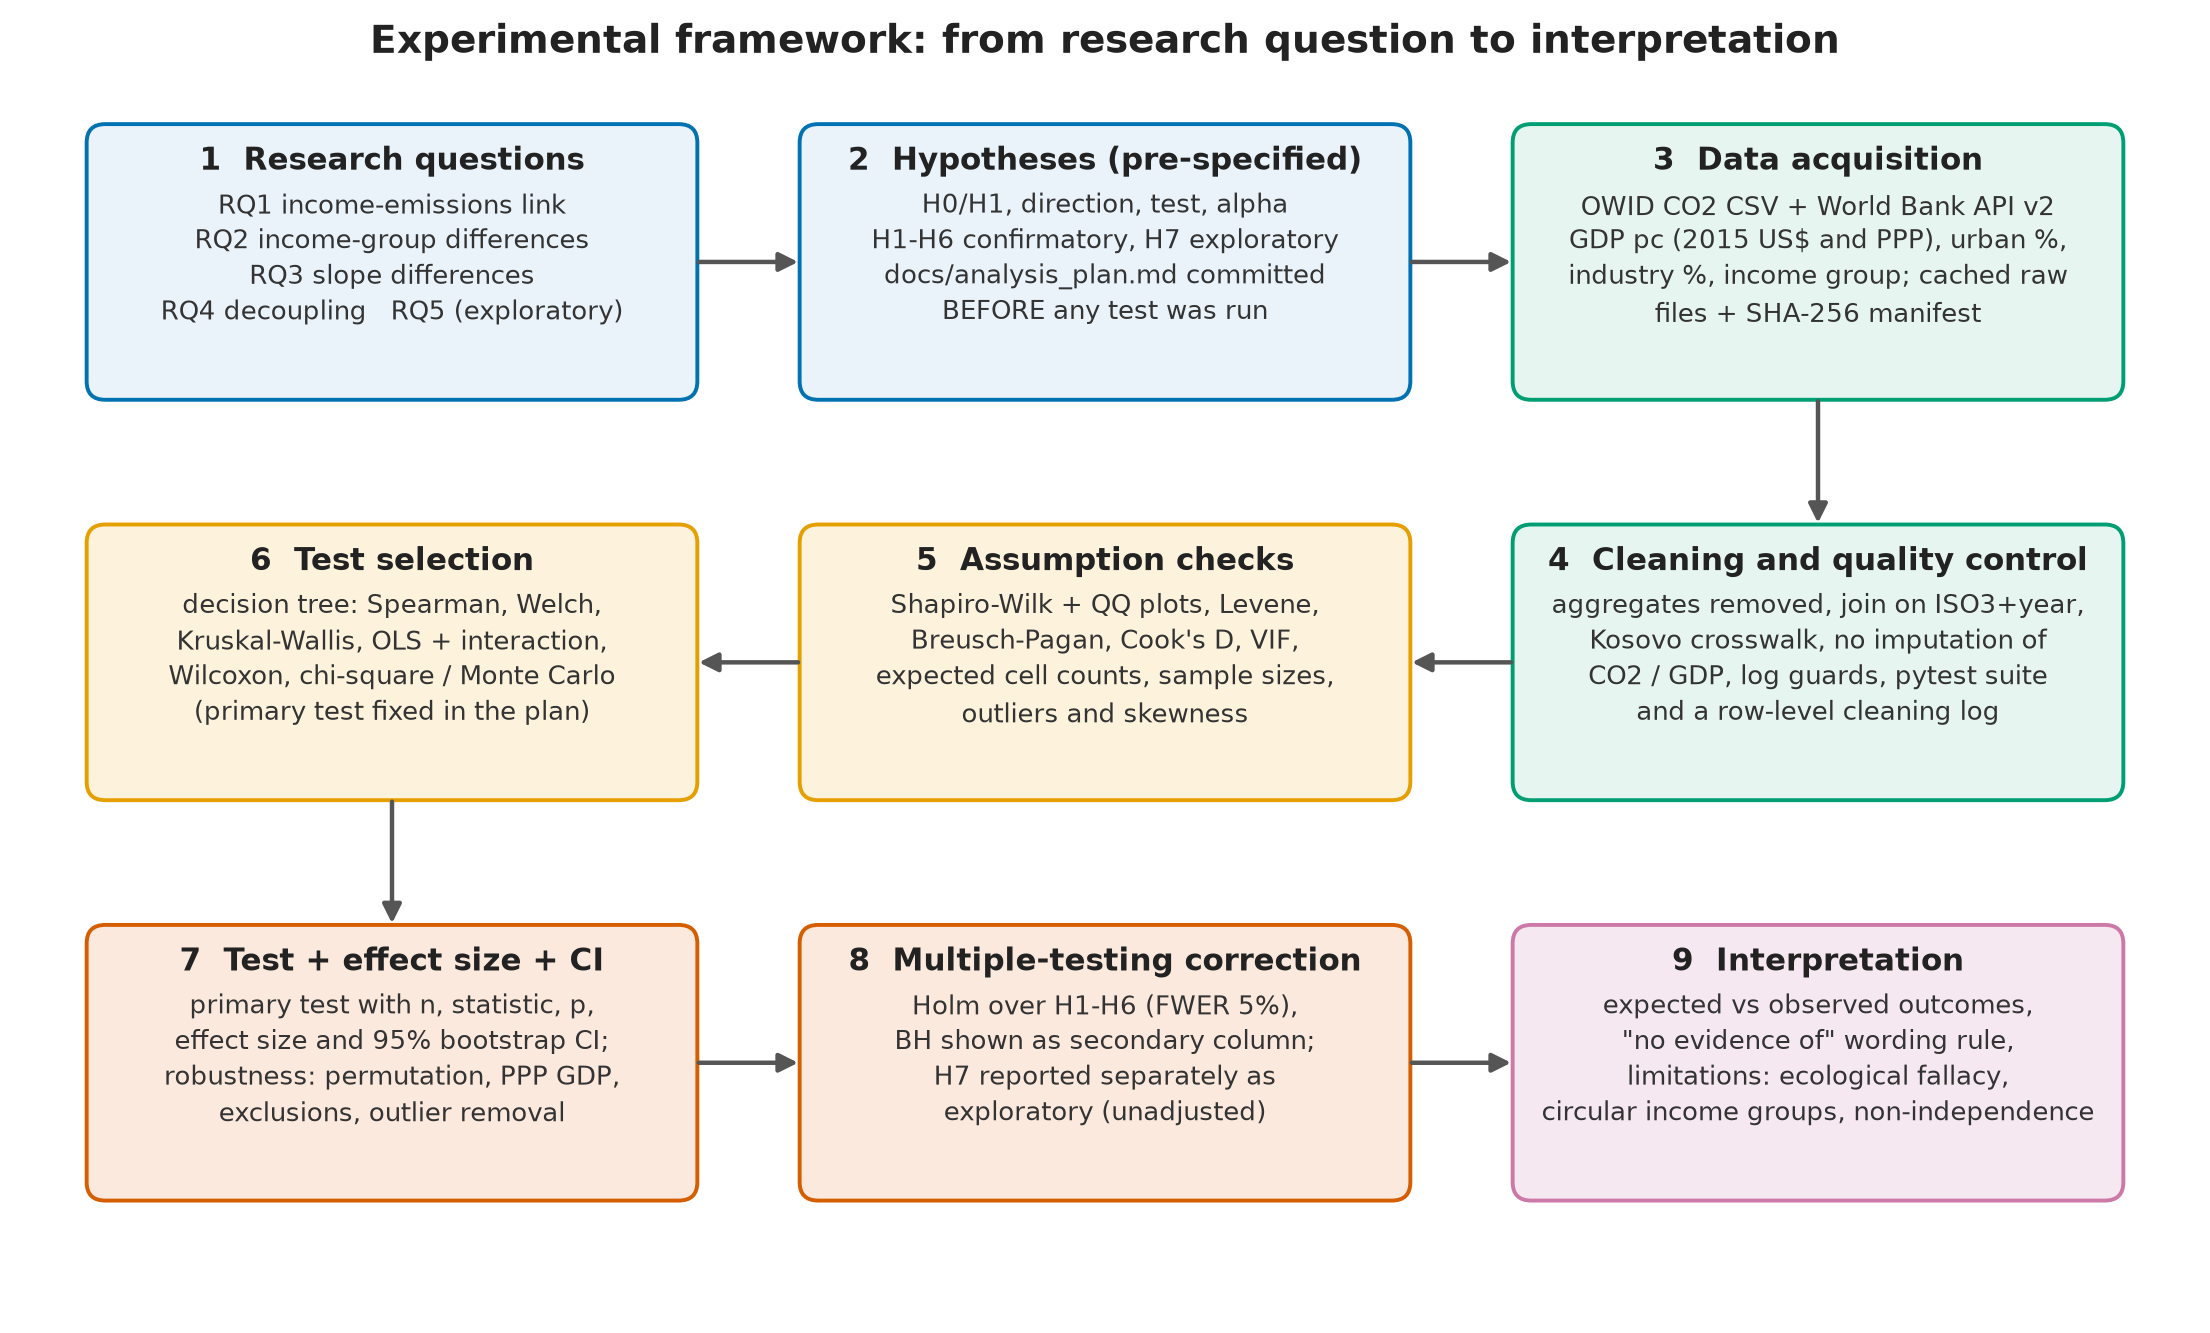

fig_test_selection_tree


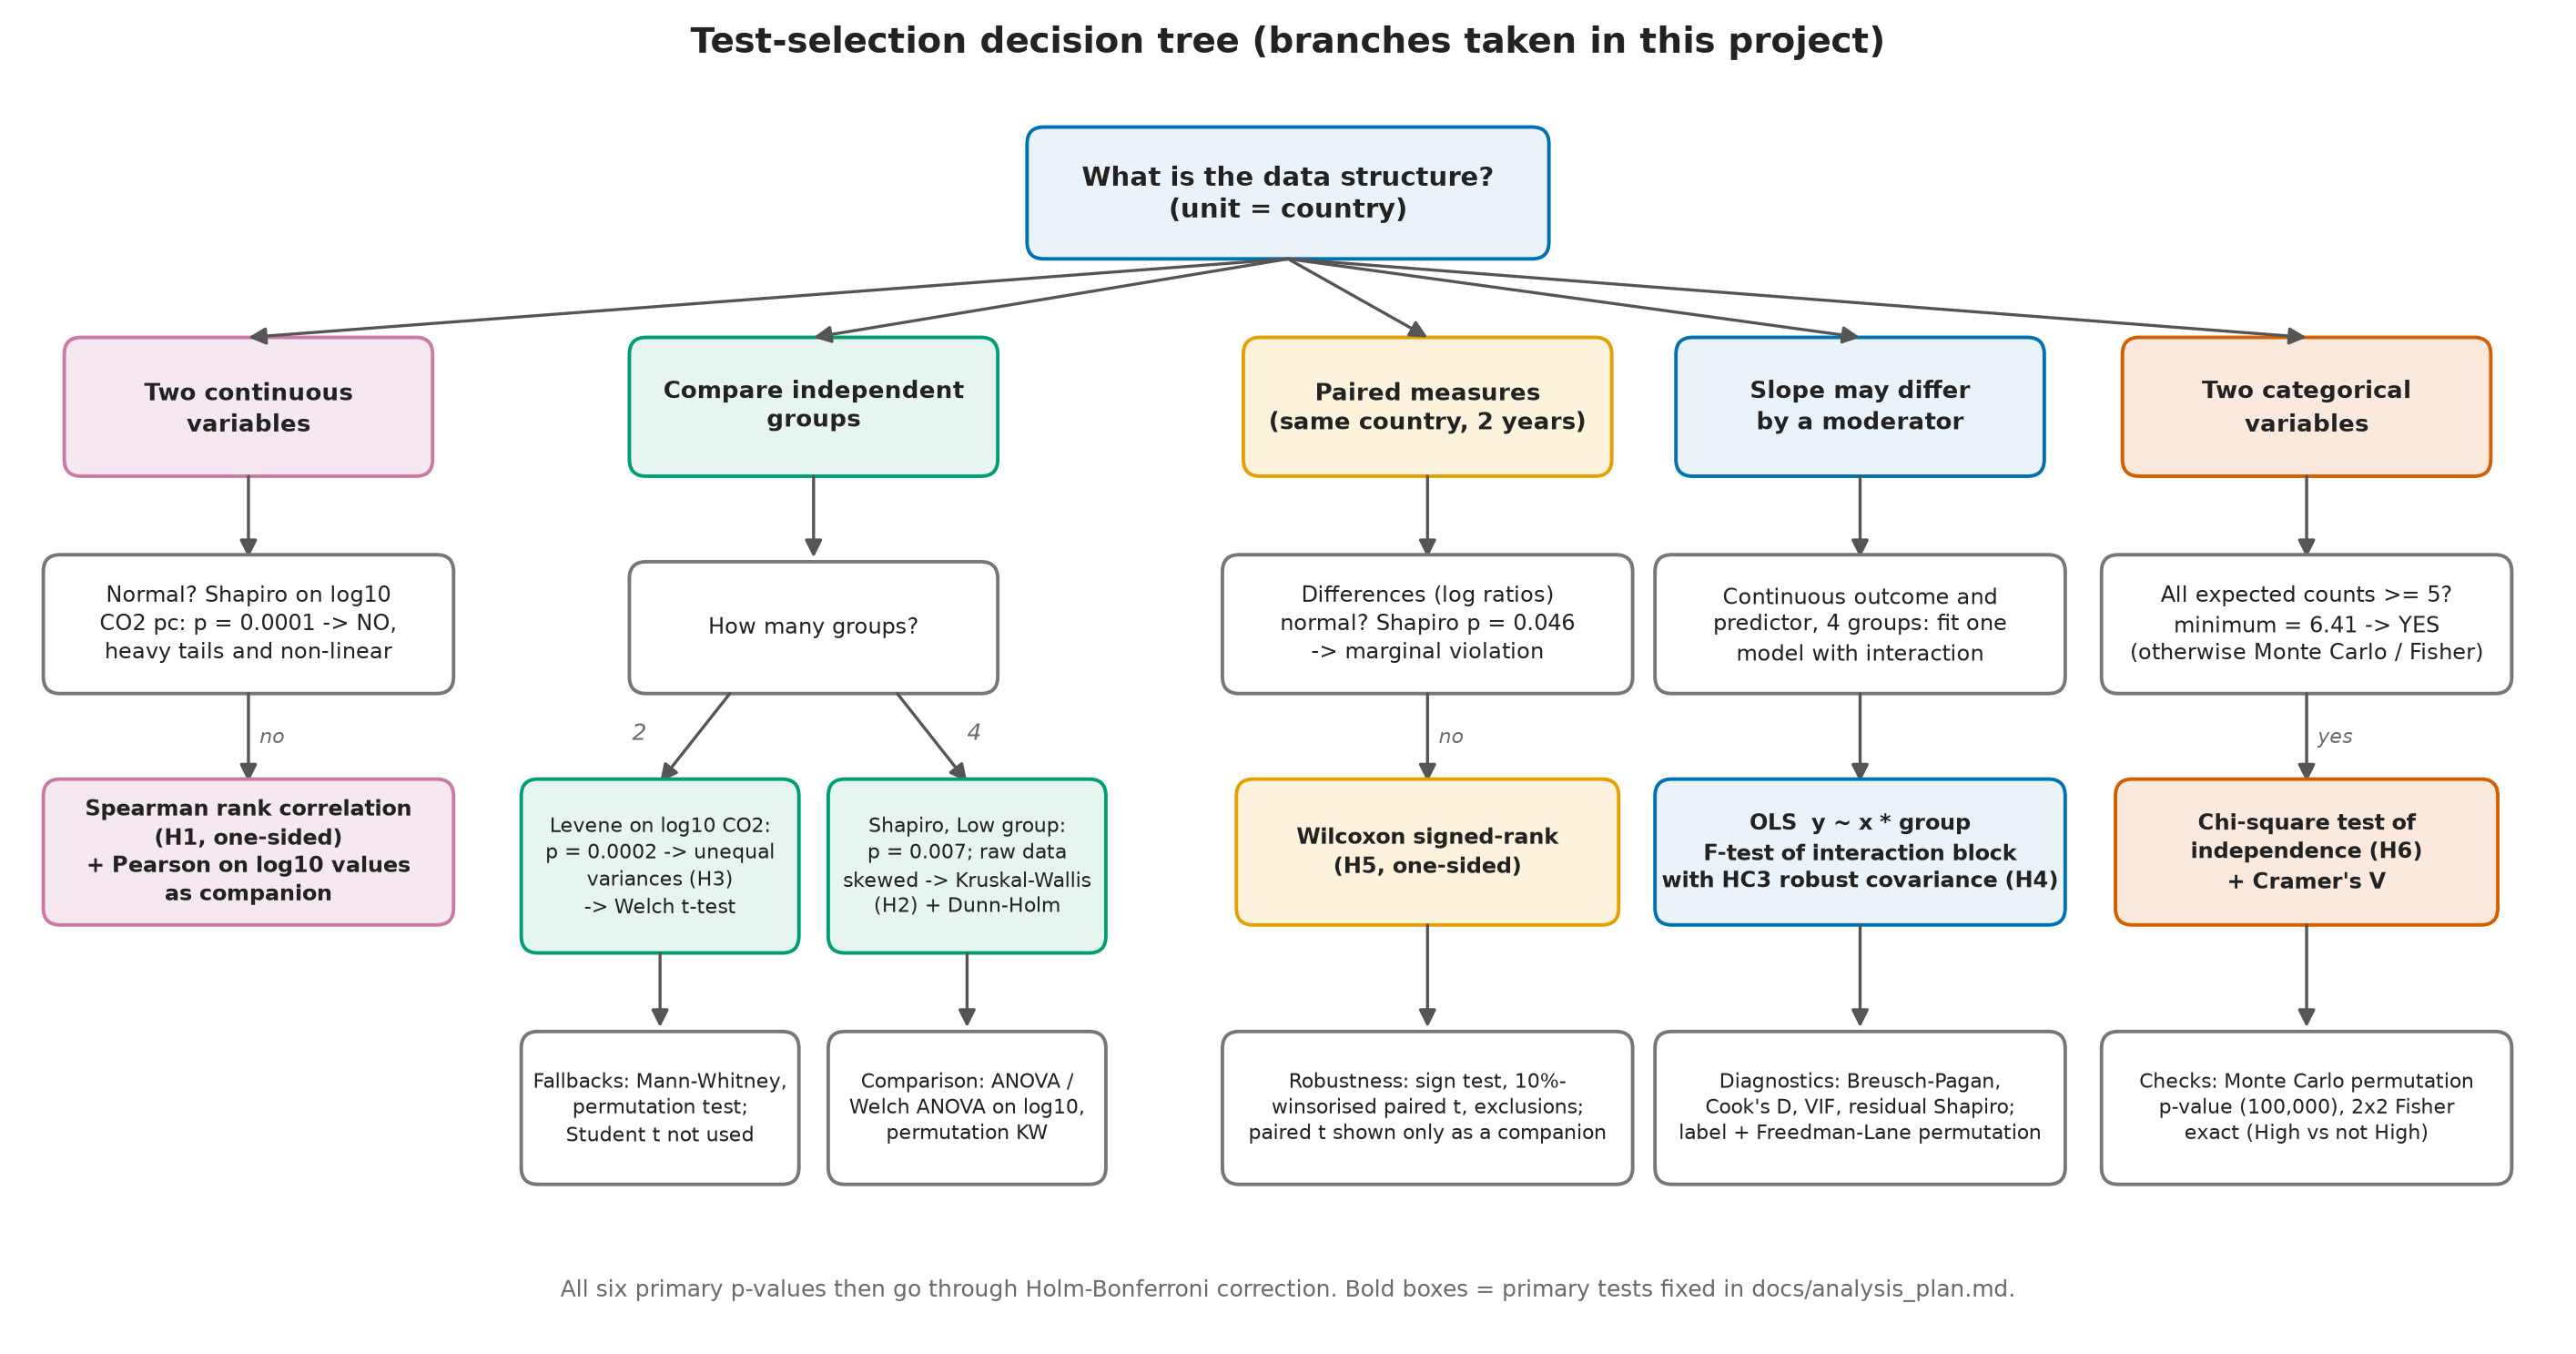

fig_assumption_checks


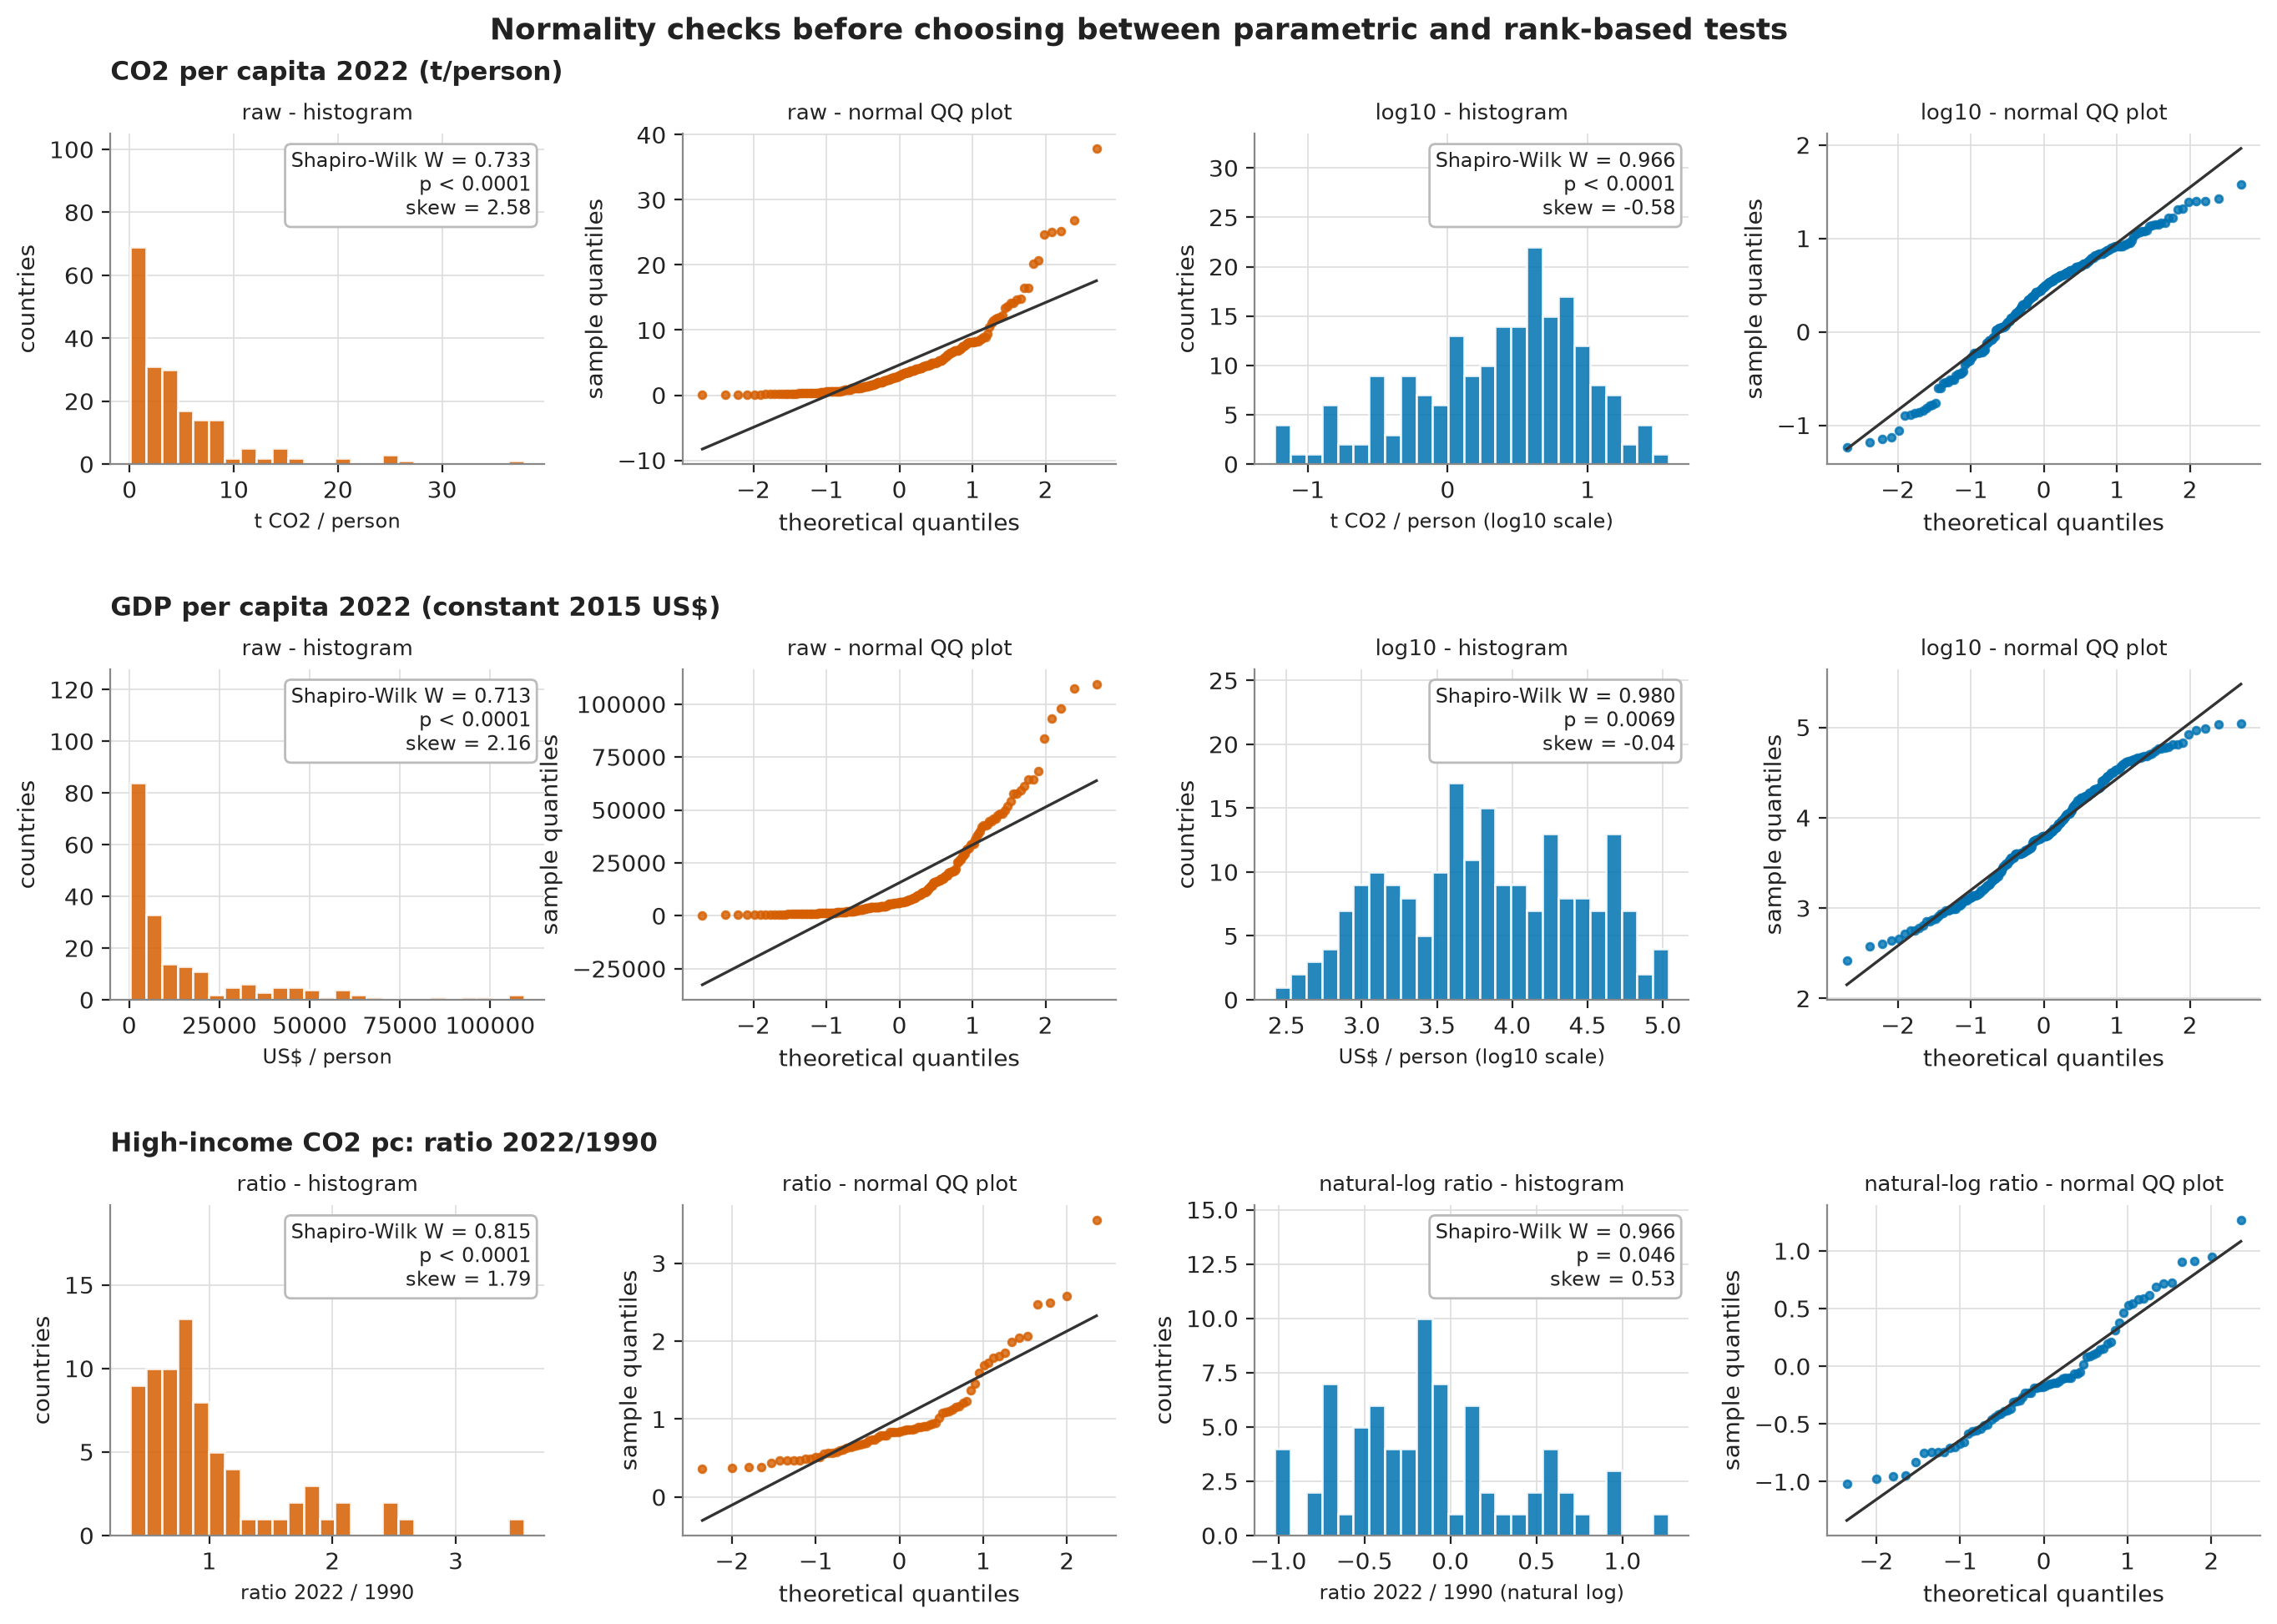

fig_h1_scatter


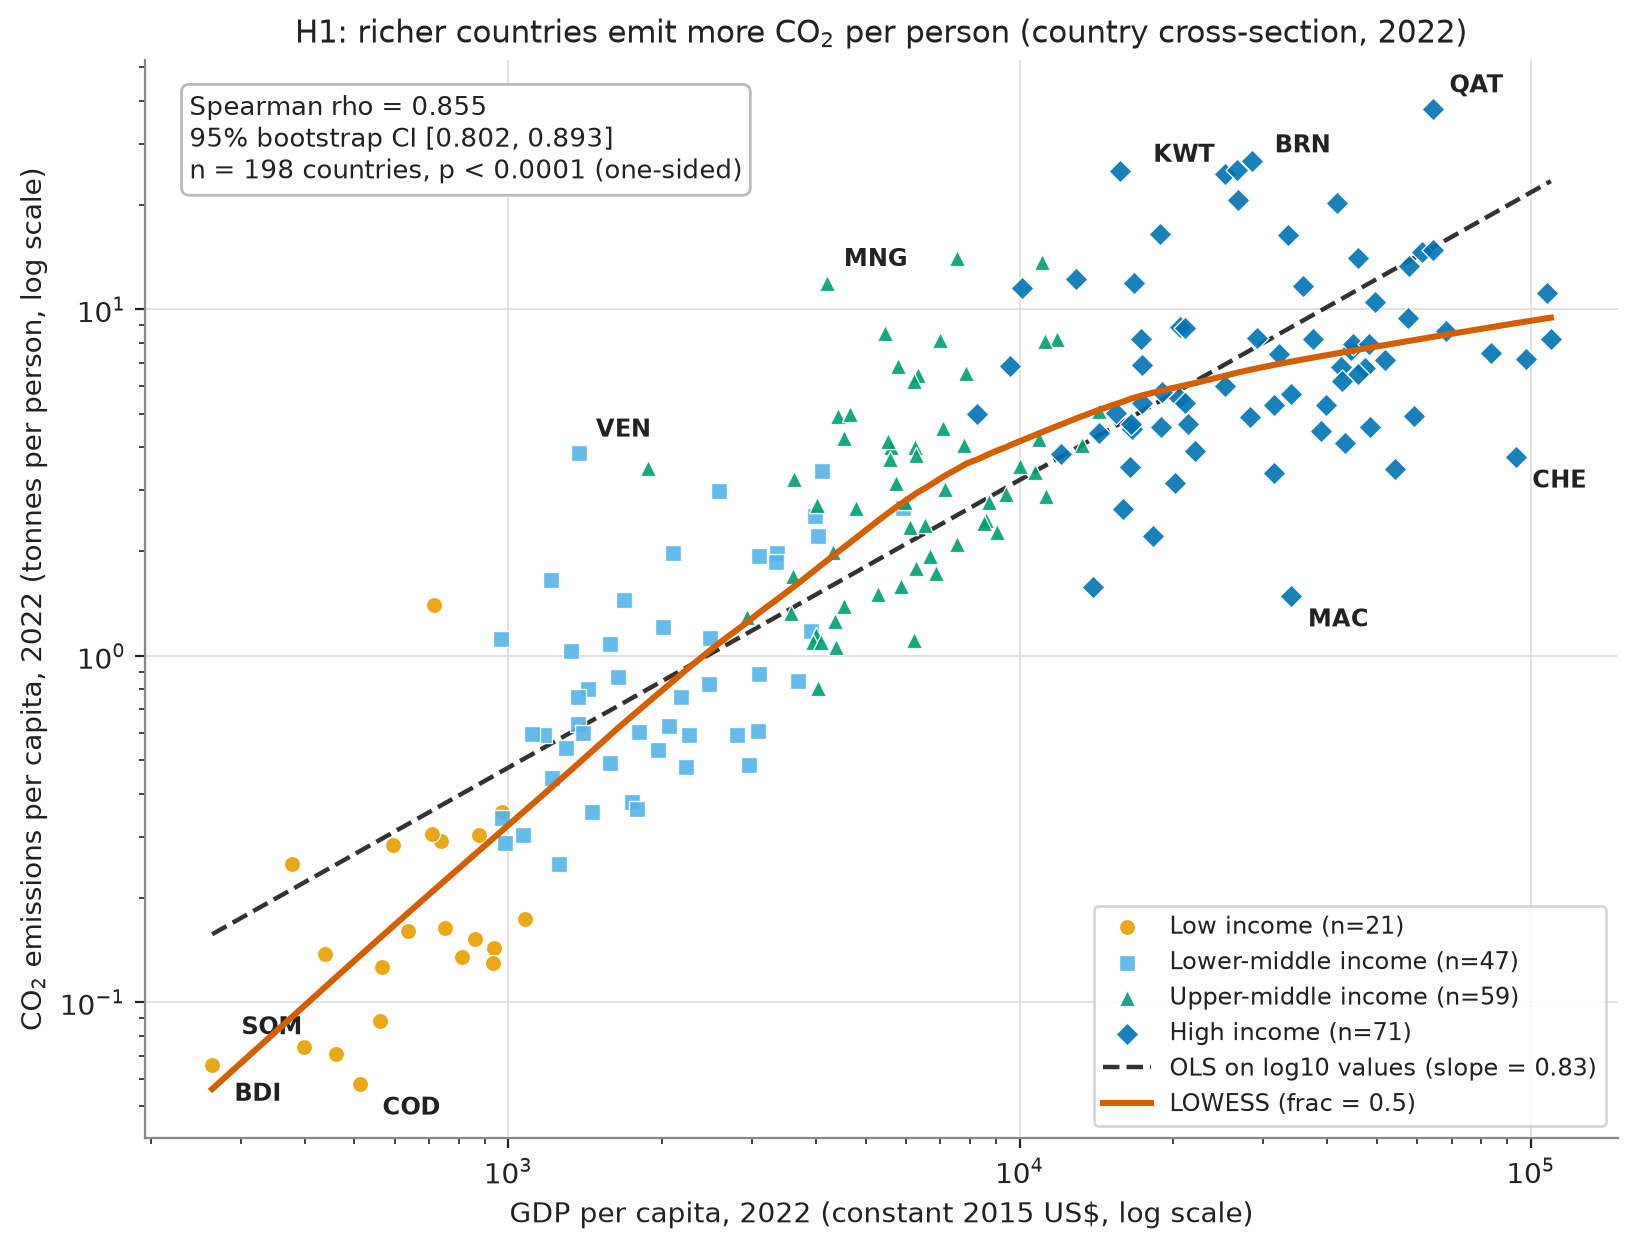

fig_h2_boxplot_by_income


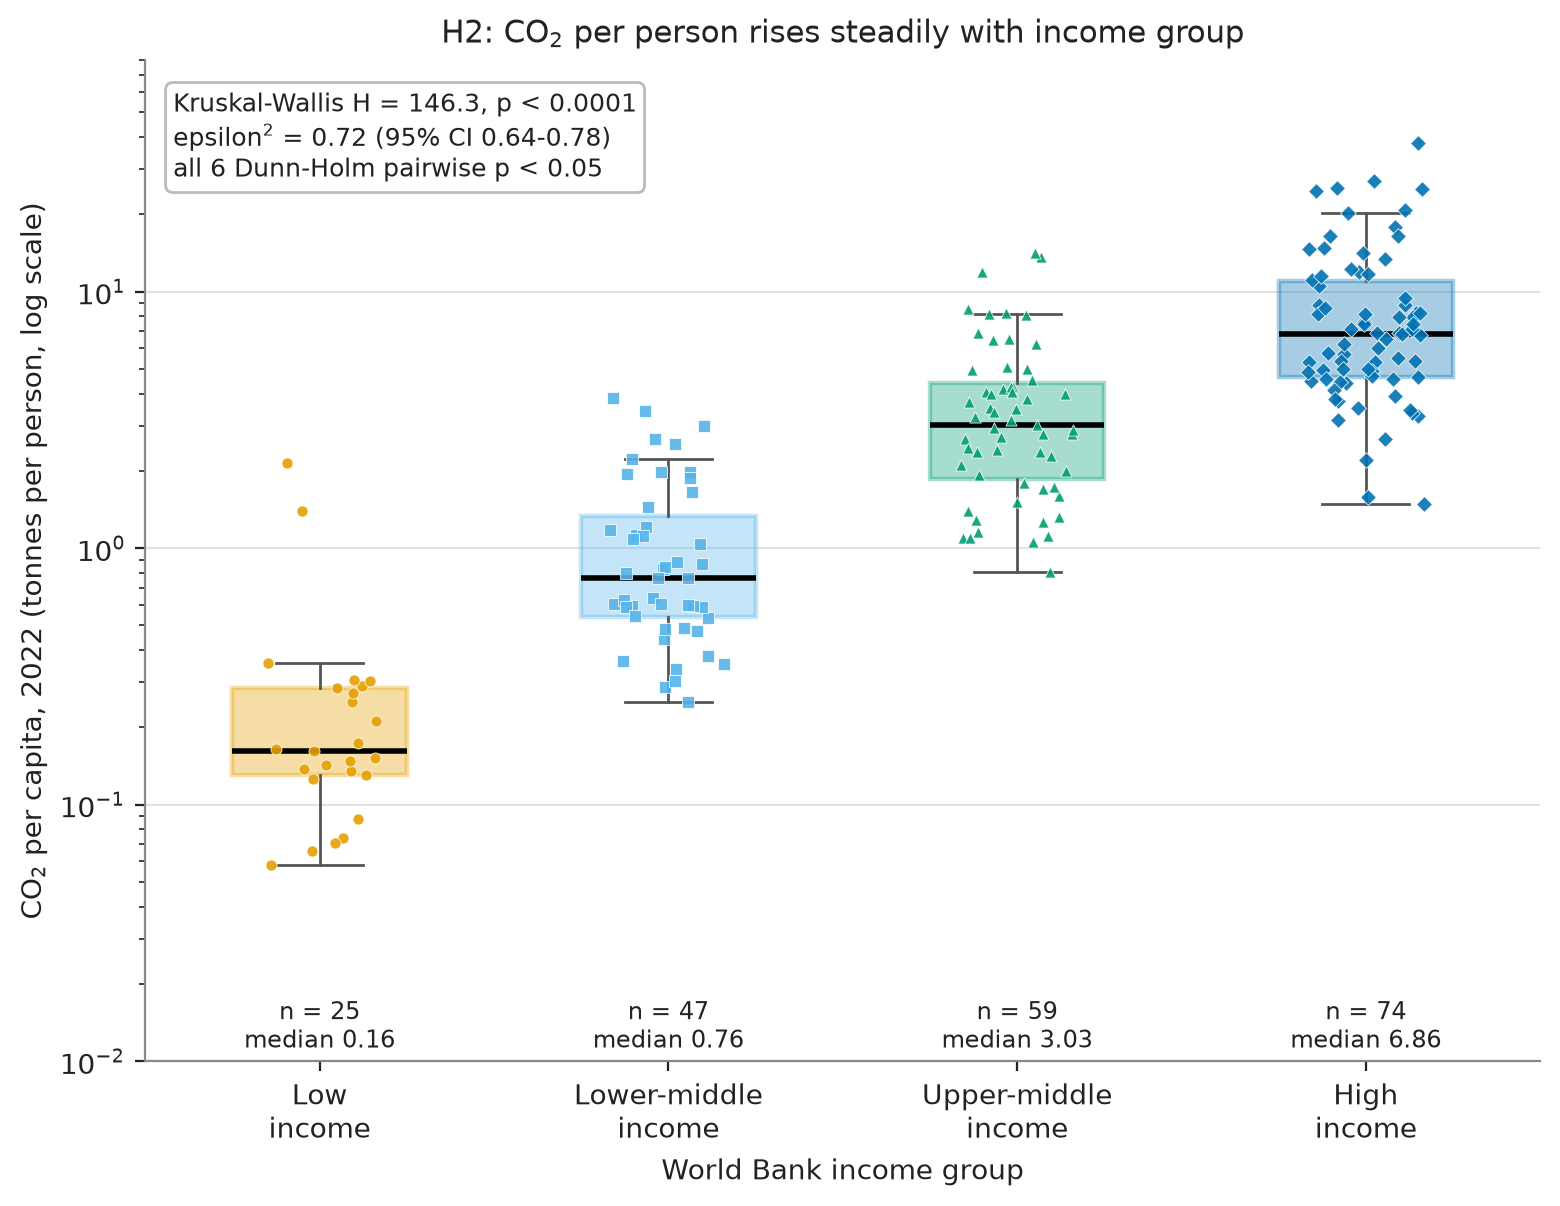

fig_h4_slopes_by_income


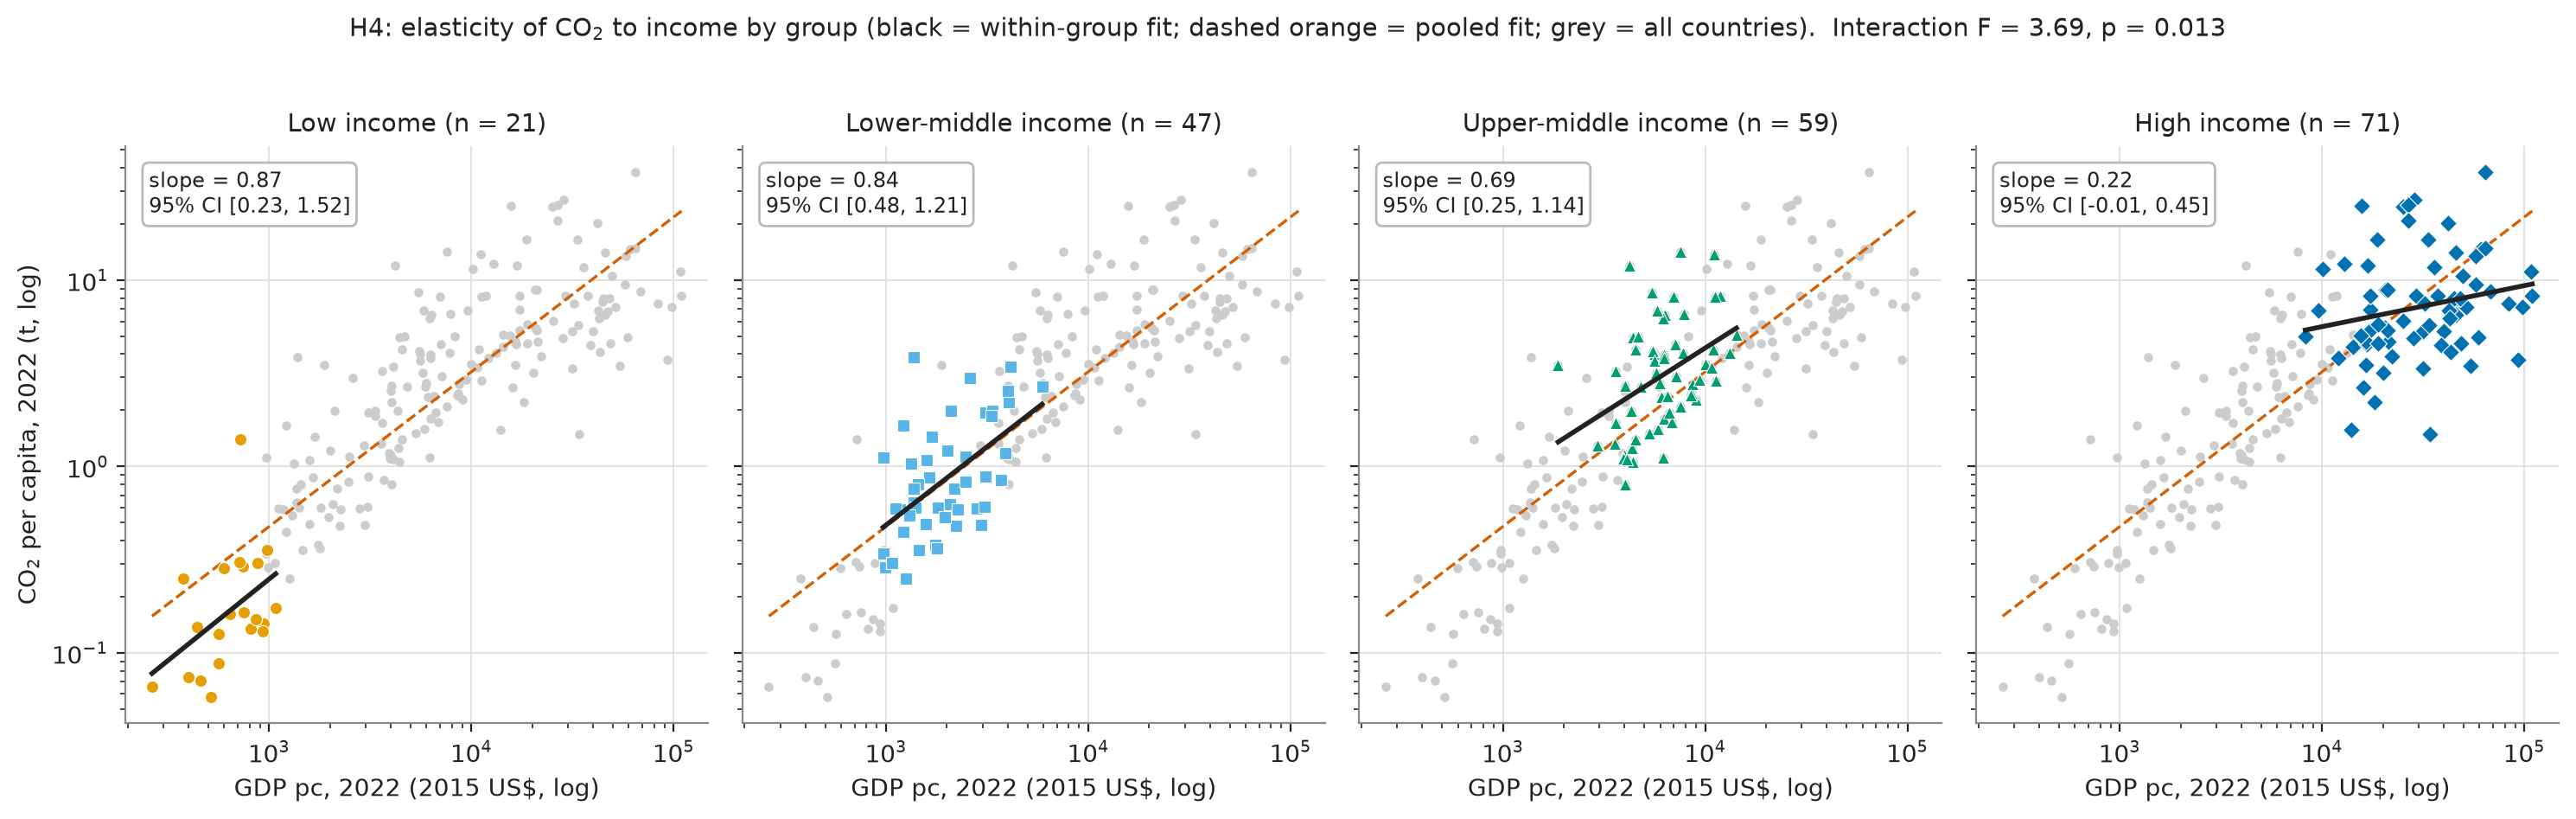

fig_h5_paired_change


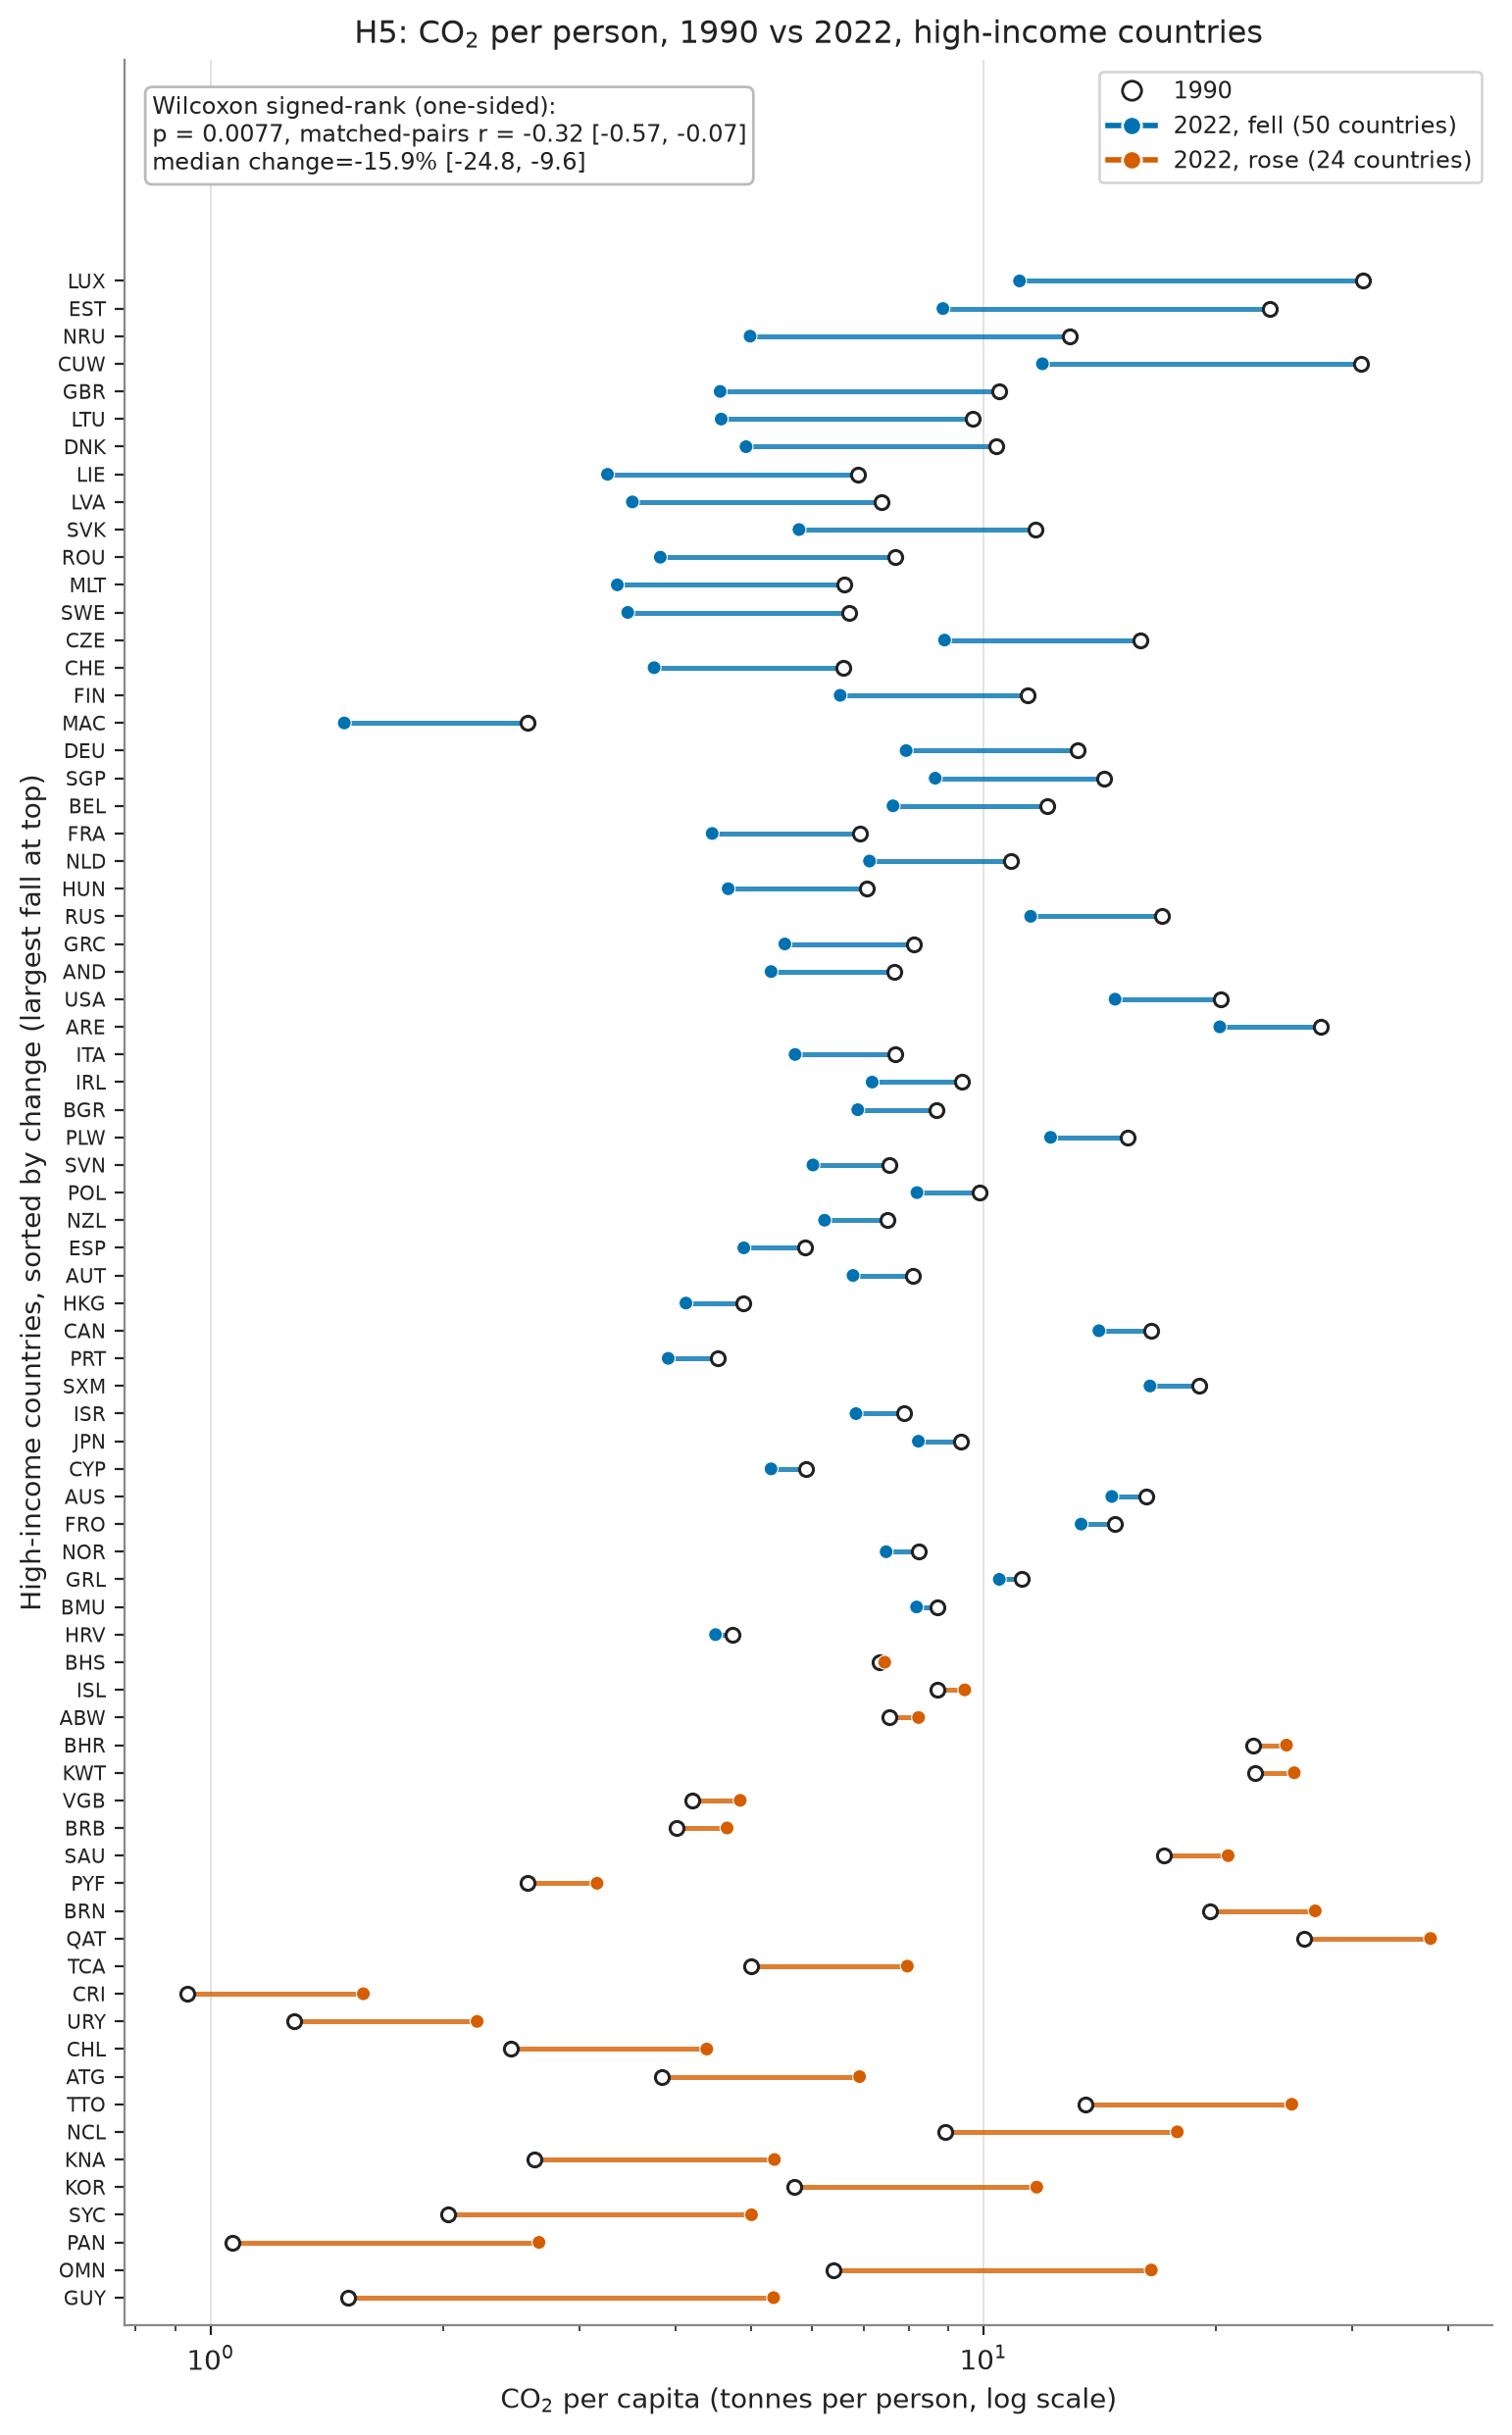

fig_h6_decoupling_heatmap


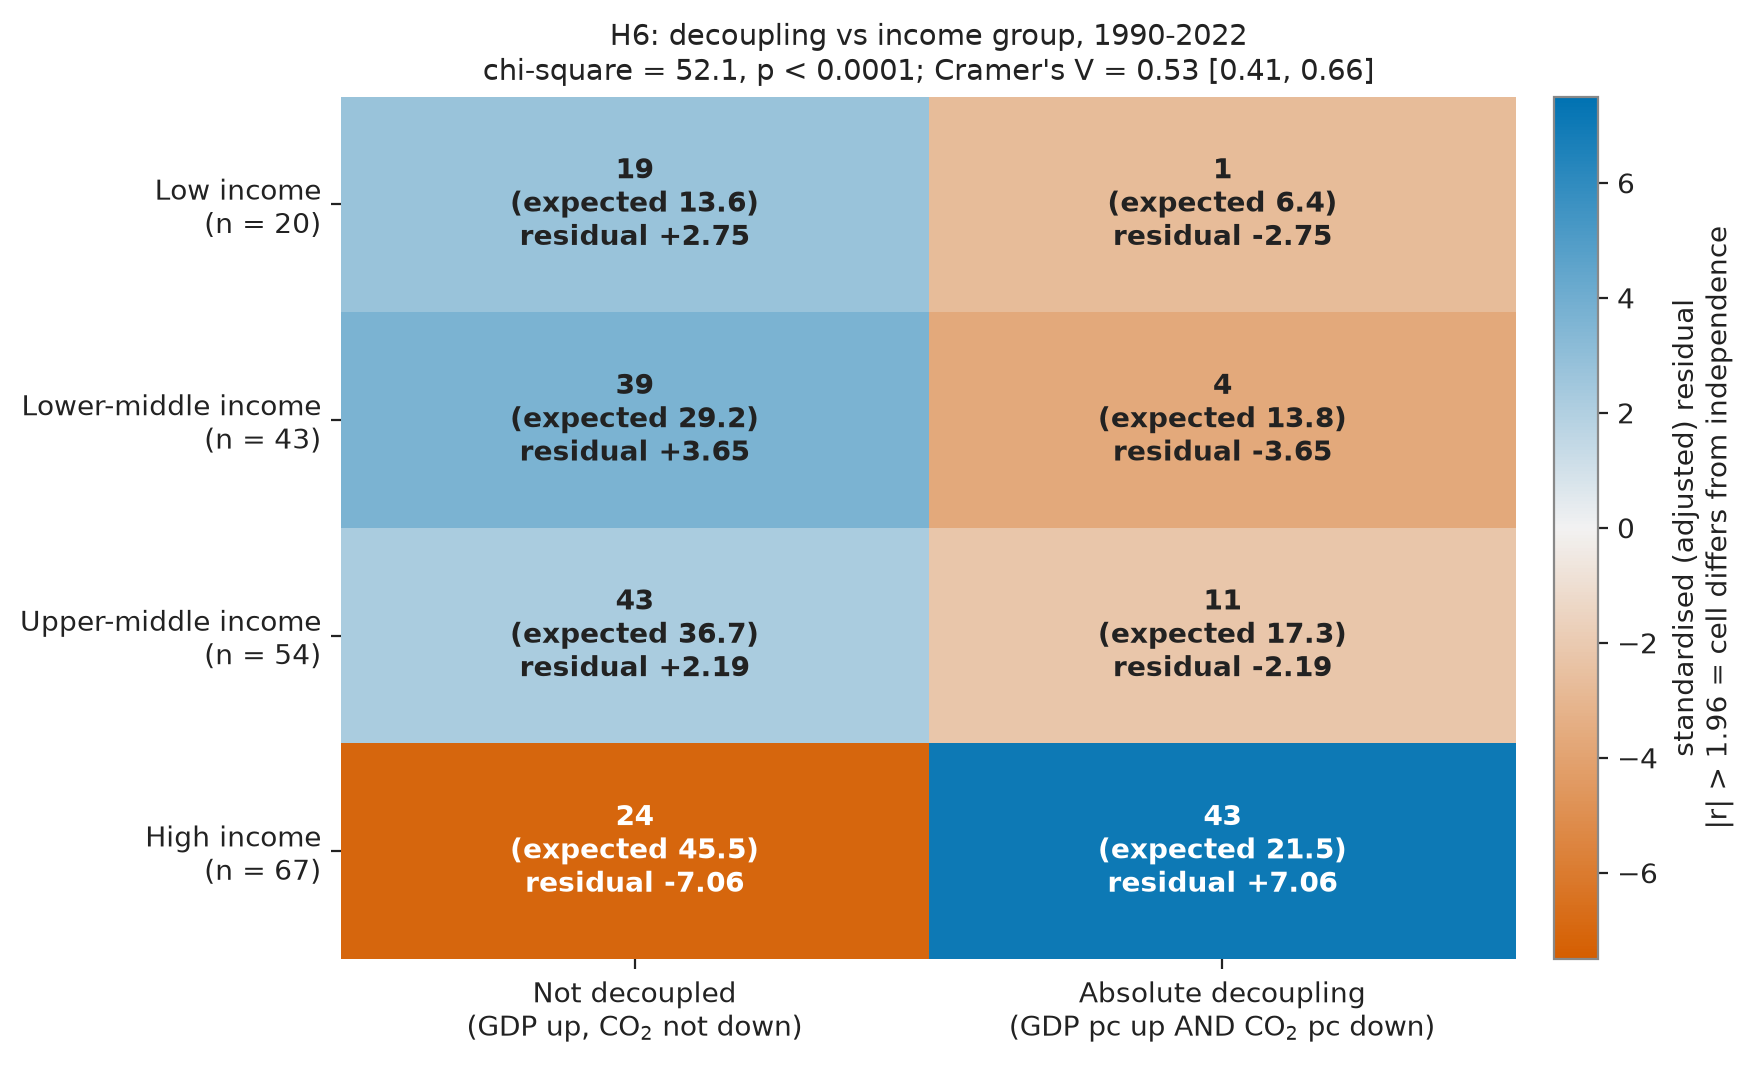

fig_effect_size_forest


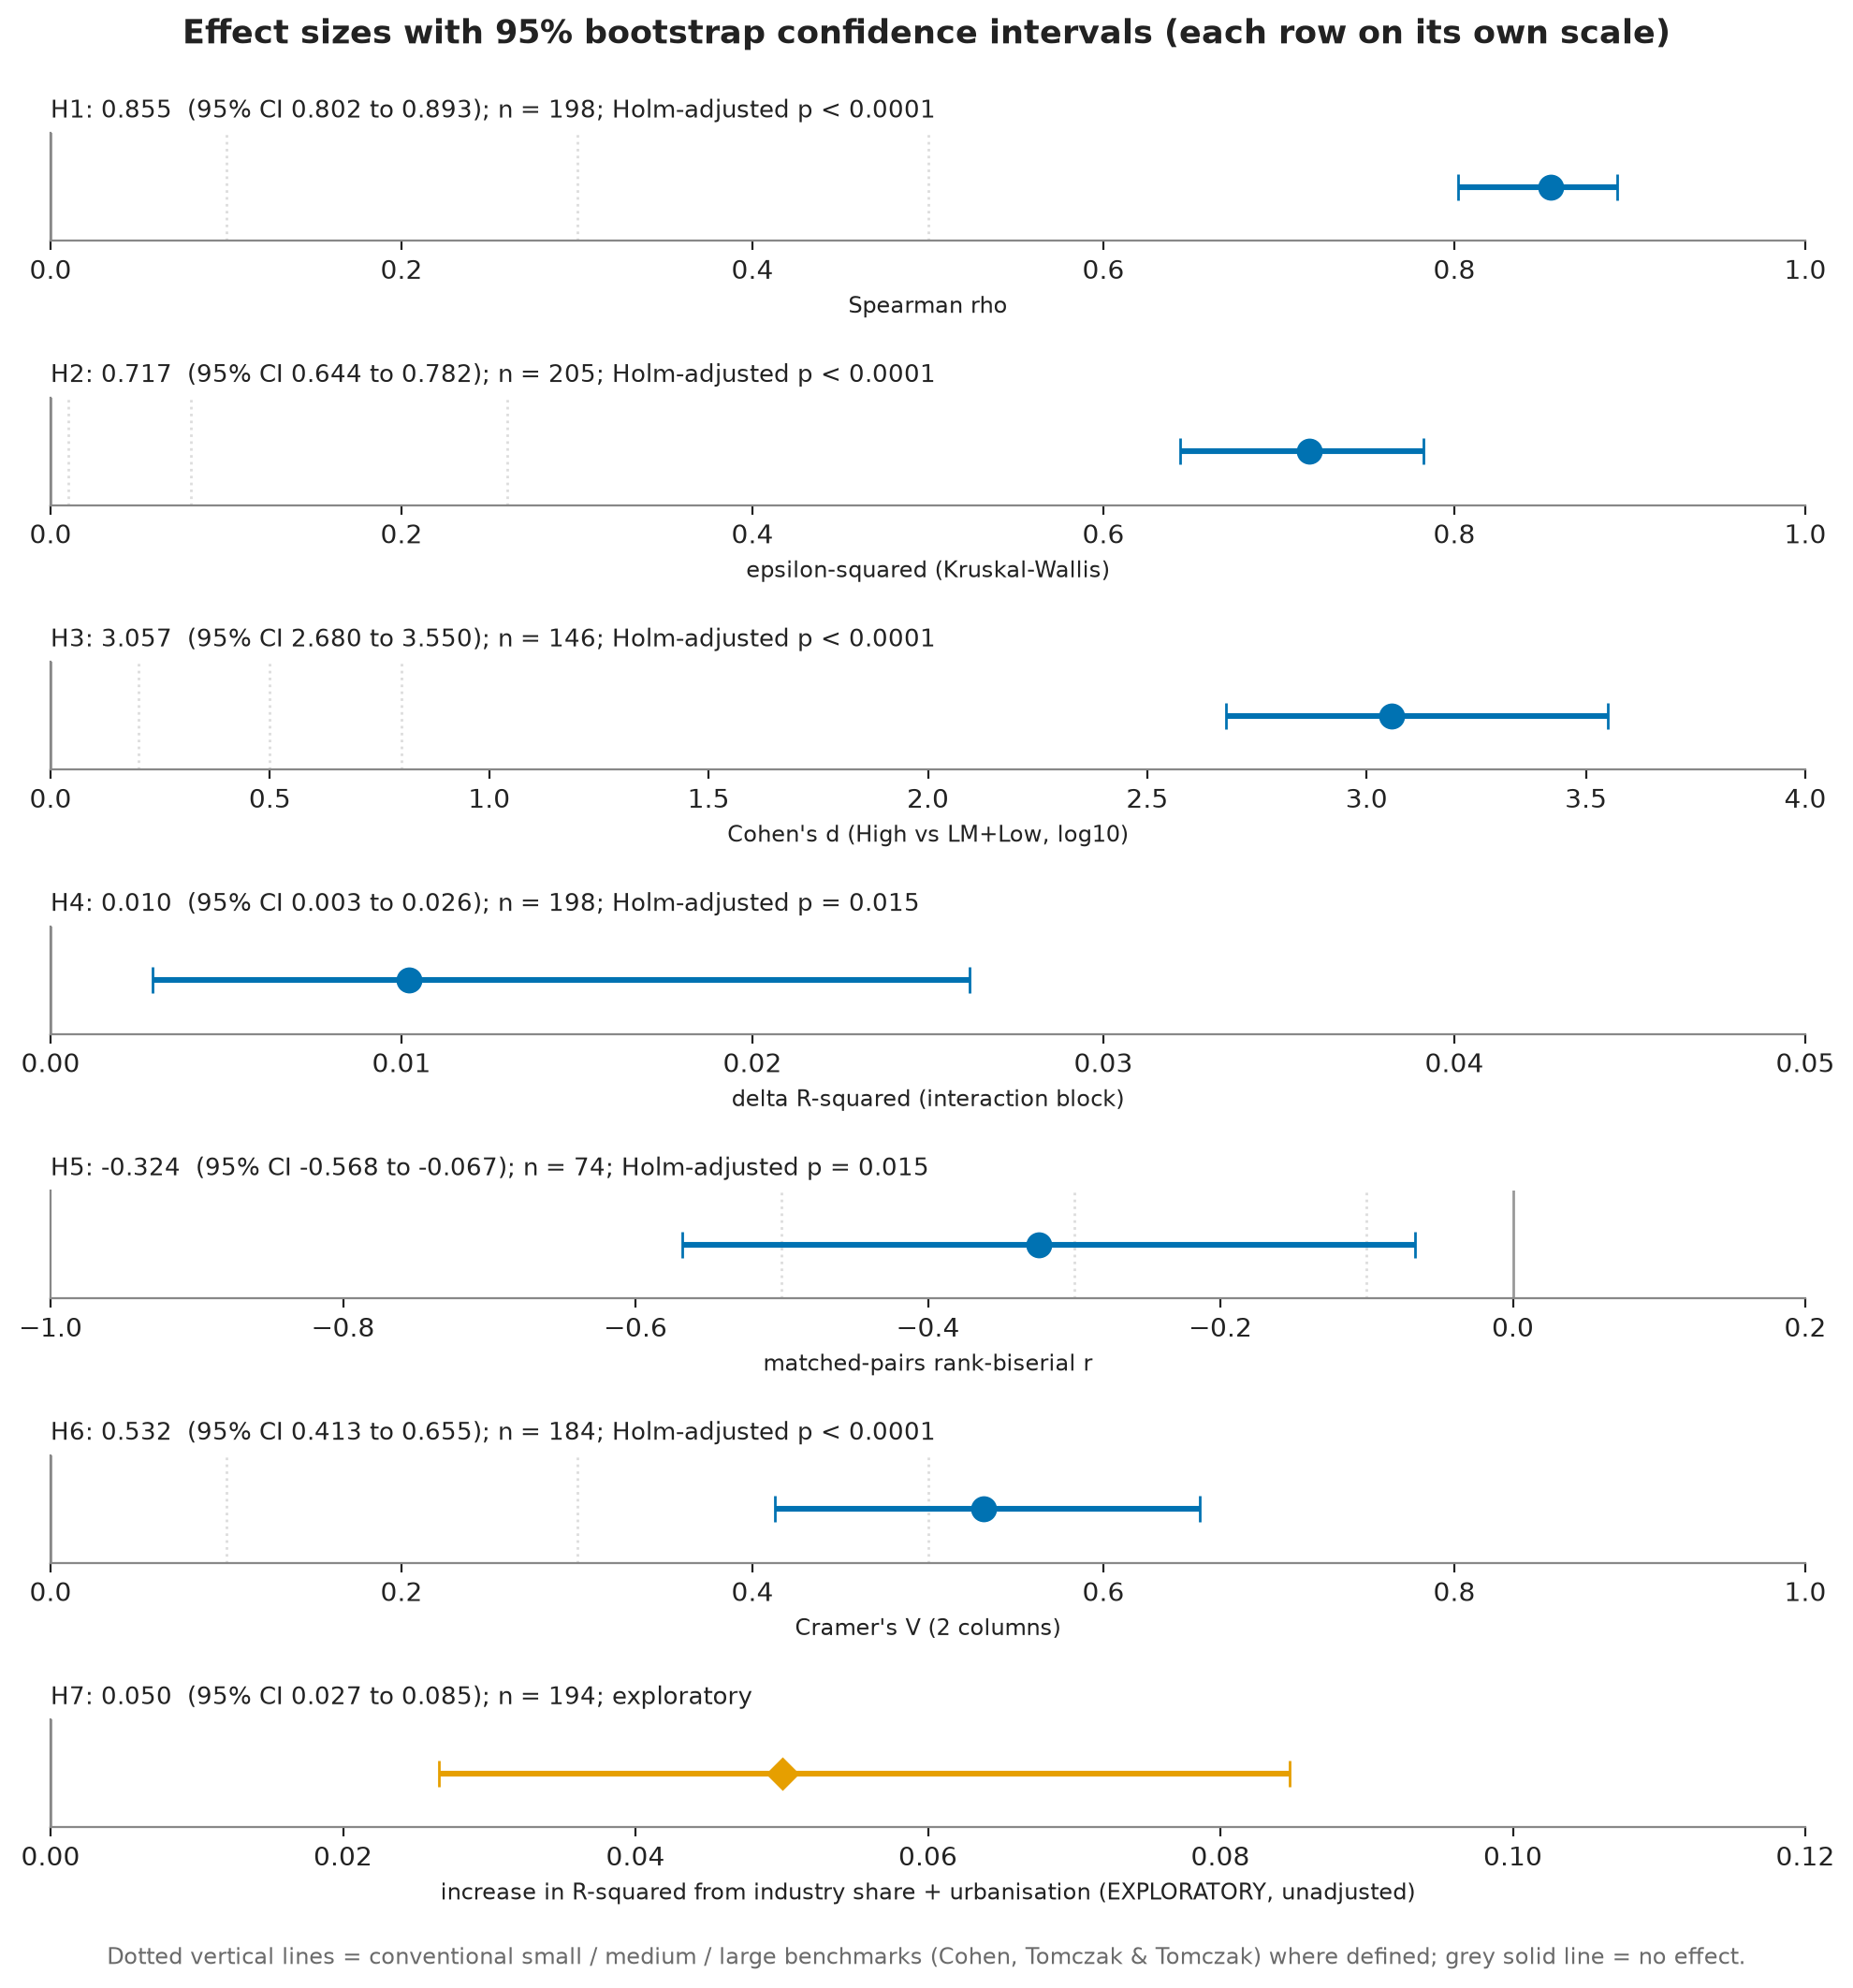

fig_power_curve


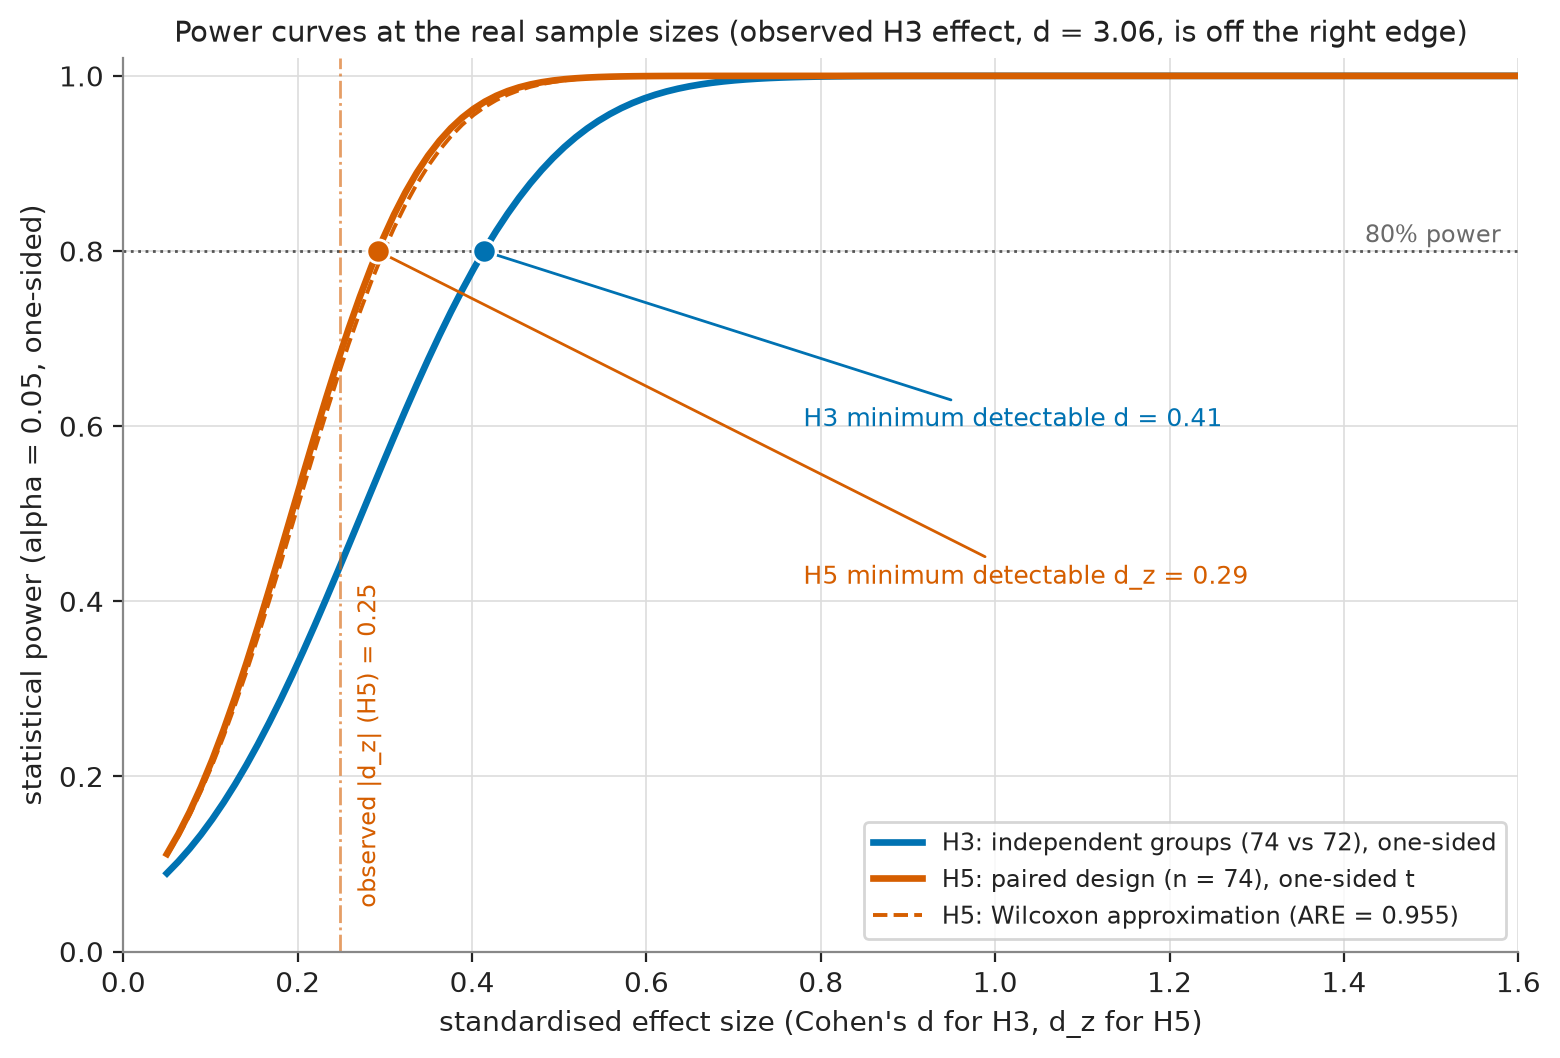

fig_timeline_gantt


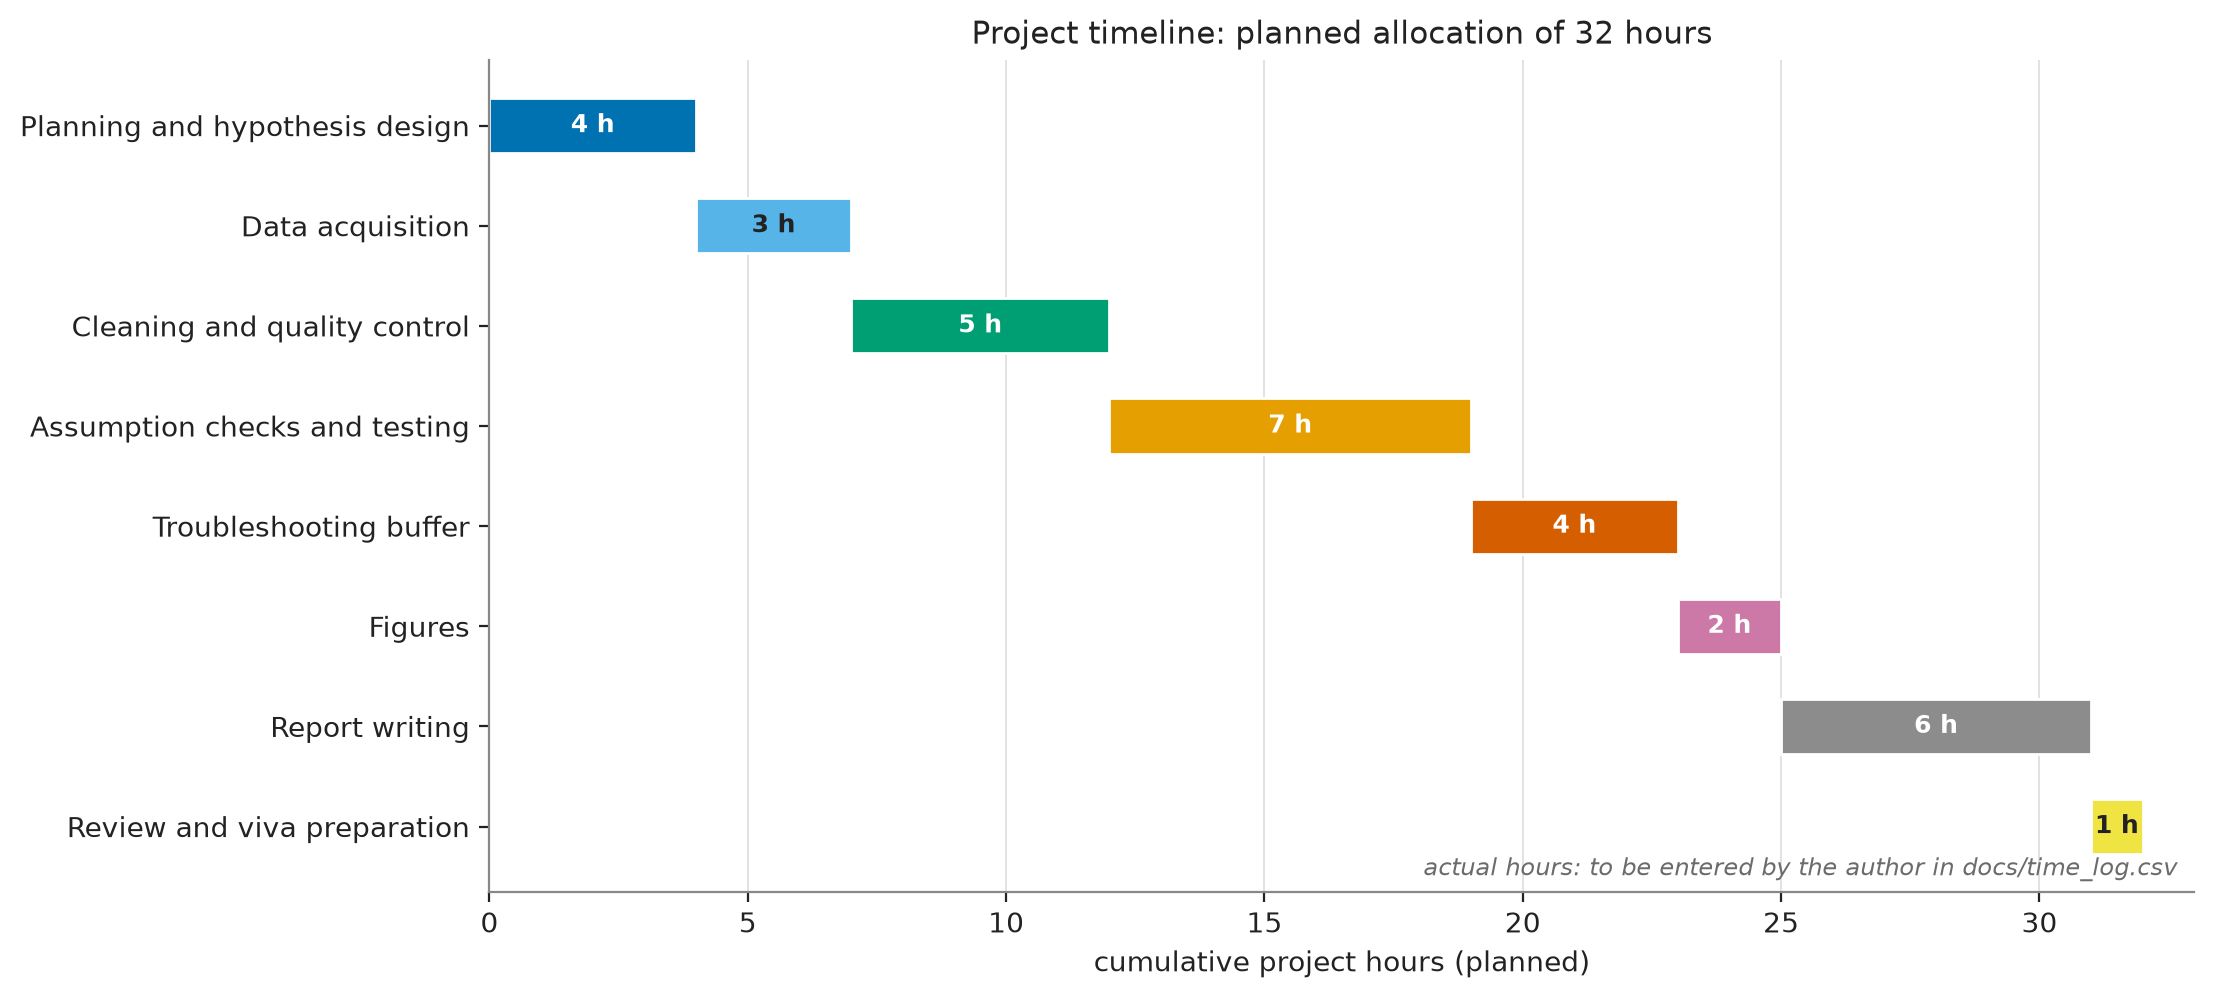

In [12]:
for name in ['fig_framework_flowchart','fig_test_selection_tree','fig_assumption_checks','fig_h1_scatter','fig_h2_boxplot_by_income','fig_h4_slopes_by_income','fig_h5_paired_change','fig_h6_decoupling_heatmap','fig_effect_size_forest','fig_power_curve','fig_timeline_gantt']:
    print(name); display(Image(filename=f'figures/{name}.png', width=800))